# Лабораторная работа 1 — рабочий ноутбук

**ФИО:** Мищенко Мария Михайловна

**Файлы данных:** S17: `clients.csv`, `transactions.csv`

Этот ноутбук — чистовой рабочий документ, а не черновик. Он должен
исполняться сверху вниз без ошибок на выданном вам **сыром** файле
и на выходе давать очищенную таблицу и `cleaning_log.csv`.

Разделы ниже обязательны, порядок менять не нужно. Внутри раздела
добавляйте столько ячеек, сколько нужно. Если какой-то раздел у вас
пустой — напишите в нём одной строкой, почему.

## 0. Окружение и настройки

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 50)

RAW_CLIENTS = "data/clients.csv"
RAW_TXN = "data/transactions.csv"

## 1. Загрузка сырых данных

Файлы выгружены разными системами. Убедитесь, что они прочитались
**правильно**: кодировка, разделитель, десятичный разделитель, типы,
даты, идентификаторы.

In [2]:
# проверка кодировок на нескольких строках данных
print("----- Clients table -----")
with open(RAW_CLIENTS, encoding='utf-8') as f:
    for _ in range(3):
        print(repr(f.readline()))

print("----- Transactions table -----")
with open(RAW_TXN, encoding='cp1251') as f:
    for _ in range(3):
        print(repr(f.readline()))

----- Clients table -----
'client_id,birth_date,gender,city,segment,loyalty_tier,card_type,registration_date,card_open_date,income_source,monthly_income,has_mobile_app,app_last_login,satisfaction_score,branch_code,marketing_opt_in\n'
'C004755,1972-02-03,Ж,МОСКВА,Премиальный,Серебро,Кредитная,19.11.2020,03.04.2022,Не указан,,Да,2024-08,,00805,Да\n'
'C004627,1976-05-16,М,Новосибирск,Зарплатный,Серебро,Дебетовая,16.06.2012,31.08.2017,Зарплата в нашем банке,61600.0,Да,2025-05,,00256,Да\n'
----- Transactions table -----
'txn_id;client_id;txn_datetime;amount;currency;category;mcc_code;channel;status\n'
'990060;C004365;2023-12-05 14:19:43;145,82;RUB;Продукты;5411;Карта;успешно\n'
'990167;C005370;2023-12-10 10:57:55;1480,83;RUB;Продукты;5411;СБП;успешно\n'


**Вывод:** файл с клиентами читается как UTF-8, разделитель — ",", дробная часть — через точку, первая строка — заголовок. Параметры `read_csv` по умолчанию подходят. Файл с транзакциями имеет другую кодировку, разделитель - ";", дробная часть через запятую => явно указываем параметры, когда читаем этот файл.

In [3]:
clients_raw = pd.read_csv(RAW_CLIENTS)
clients = clients_raw.copy()
clients_raw.head()

,client_id,birth_date,gender,city,segment,loyalty_tier,card_type,registration_date,card_open_date,income_source,monthly_income,has_mobile_app,app_last_login,satisfaction_score,branch_code,marketing_opt_in
0,C004755,1972-02-03,Ж,МОСКВА,Премиальный,Серебро,Кредитная,19.11.2020,03.04.2022,Не указан,NaN,Да,2024-08,NaN,805,Да
1,C004627,1976-05-16,М,Новосибирск,Зарплатный,Серебро,Дебетовая,16.06.2012,31.08.2017,Зарплата в нашем банке,61600.0,Да,2025-05,NaN,256,Да
2,C001846,1962-06-17,М,Москва,Зарплатный,Серебро,Дебетовая,10.07.2019,03.11.2021,Зарплата в нашем банке,102900.0,Нет,NaN,NaN,198,Да
3,C004355,1978-03-05,М,Москва,Зарплатный,Золото,Дебетовая,13.10.2024,08.02.2025,Зарплата в нашем банке,85100.0,Да,2024-04,NaN,927,Да
4,C004093,1992-10-13,Ж,СПб,Массовый,Базовый,Дебетовая,27.08.2015,24.09.2017,Зарплата в нашем банке,47900.0,Да,2024-03,NaN,171,Да


In [4]:
transactions_raw = pd.read_csv(RAW_TXN, encoding='cp1251', sep=';', decimal=',')
transactions = transactions_raw.copy()
transactions_raw.head()

,txn_id,client_id,txn_datetime,amount,currency,category,mcc_code,channel,status
0,990060,C004365,2023-12-05 14:19:43,145.82,RUB,Продукты,5411,Карта,успешно
1,990167,C005370,2023-12-10 10:57:55,1480.83,RUB,Продукты,5411,СБП,успешно
2,990142,C005487,2023-12-12,530.24,RUB,Продукты,5411,Карта,успешно
3,100001,C000952,2024-01-01 00:08:10,518.25,RUB,Кафе/рестораны,5812,Онлайн-банк,успешно
4,100002,C000498,2024-01-01 01:53:31,896.19,RUB,Продукты,5411,Онлайн-банк,успешно


## 2. Аудит качества

Здесь вы ничего не исправляете — только находите и измеряете.
Для каждой метрики качества заранее определите знаменатель.

### 2.1. Объём, типы, ключи, единица наблюдения

**Clients table**

In [11]:
print("Объём: ", clients.shape)
clients.head()

Объём:  (5715, 16)


,client_id,birth_date,gender,city,segment,loyalty_tier,card_type,registration_date,card_open_date,income_source,monthly_income,has_mobile_app,app_last_login,satisfaction_score,branch_code,marketing_opt_in
0,C004755,1972-02-03,Ж,МОСКВА,Премиальный,Серебро,Кредитная,19.11.2020,03.04.2022,Не указан,NaN,Да,2024-08,NaN,805,Да
1,C004627,1976-05-16,М,Новосибирск,Зарплатный,Серебро,Дебетовая,16.06.2012,31.08.2017,Зарплата в нашем банке,61600.0,Да,2025-05,NaN,256,Да
2,C001846,1962-06-17,М,Москва,Зарплатный,Серебро,Дебетовая,10.07.2019,03.11.2021,Зарплата в нашем банке,102900.0,Нет,NaN,NaN,198,Да
3,C004355,1978-03-05,М,Москва,Зарплатный,Золото,Дебетовая,13.10.2024,08.02.2025,Зарплата в нашем банке,85100.0,Да,2024-04,NaN,927,Да
4,C004093,1992-10-13,Ж,СПб,Массовый,Базовый,Дебетовая,27.08.2015,24.09.2017,Зарплата в нашем банке,47900.0,Да,2024-03,NaN,171,Да


In [12]:
clients_overview = pd.DataFrame({
    "dtype": clients.dtypes,
    "n_unique": clients.nunique(),
    "n_missing": clients.isna().sum(),
    'missing_%': (clients.isna().mean() * 100).round(2),
})
clients_overview

,dtype,n_unique,n_missing,missing_%
client_id,str,5660,0,0.00
birth_date,str,4846,0,0.00
gender,str,2,0,0.00
city,str,17,0,0.00
segment,str,4,0,0.00
loyalty_tier,str,4,0,0.00
card_type,str,3,0,0.00
registration_date,str,3267,0,0.00
card_open_date,str,2642,0,0.00
income_source,str,3,0,0.00


In [546]:
clients.describe(include=['float64'])

,monthly_income
count,5161.000000
mean,95110.636524
std,83253.057907
min,-999.000000
25%,52600.000000
50%,72800.000000
75%,108000.000000
max,991300.000000


**Transactions table**

In [14]:
print("Объём: ", transactions.shape)
transactions.head()

Объём:  (616993, 9)


,txn_id,client_id,txn_datetime,amount,currency,category,mcc_code,channel,status
0,990060,C004365,2023-12-05 14:19:43,145.82,RUB,Продукты,5411,Карта,успешно
1,990167,C005370,2023-12-10 10:57:55,1480.83,RUB,Продукты,5411,СБП,успешно
2,990142,C005487,2023-12-12,530.24,RUB,Продукты,5411,Карта,успешно
3,100001,C000952,2024-01-01 00:08:10,518.25,RUB,Кафе/рестораны,5812,Онлайн-банк,успешно
4,100002,C000498,2024-01-01 01:53:31,896.19,RUB,Продукты,5411,Онлайн-банк,успешно


In [15]:
transactions_overview = pd.DataFrame({
    "dtype": transactions.dtypes,
    "n_unique": transactions.nunique(),
    "n_missing": transactions.isna().sum()
})
transactions_overview

,dtype,n_unique,n_missing
txn_id,int64,615493,0
client_id,str,5991,0
txn_datetime,str,560854,0
amount,float64,324291,0
currency,str,3,0
category,str,12,0
mcc_code,int64,9,0
channel,str,4,0
status,str,3,0


In [16]:
transactions.describe(include=['float64'])

,amount
count,616993.000000
mean,1887.642972
std,2745.238445
min,-62286.590000
25%,468.710000
50%,1069.640000
75%,2275.320000
max,116052.630000


### 2.2. Дубли

In [17]:
print("Полные дубликаты строк в clients: ", clients.duplicated().sum())
print("Полные дубликаты строк в transactions: ", transactions.duplicated().sum())

Полные дубликаты строк в clients:  40
Полные дубликаты строк в transactions:  1283


### 2.3. Соответствие данных описанию полей из задания

**Clients**

In [18]:
clients.columns

Index(['client_id', 'birth_date', 'gender', 'city', 'segment', 'loyalty_tier', 'card_type', 'registration_date', 'card_open_date', 'income_source',
       'monthly_income', 'has_mobile_app', 'app_last_login', 'satisfaction_score', 'branch_code', 'marketing_opt_in'],
      dtype='str')

In [19]:
# 1. проверка соответсвия категорий в признаках, для которых указан чёткий список возможных значений категории
multi_category_columns = ["segment", "loyalty_tier", "card_type", "satisfaction_score"]
for col in multi_category_columns:
    print(f"{col}: {clients[col].unique().tolist()}\n")
    display(pd.DataFrame({
        'count': clients[col].value_counts(dropna=False),
        'freq': clients[col].value_counts(normalize=True).round(3)
    }))

# 2. проверка значений булевых признаков
boolean_columns = ["gender", "has_mobile_app", "marketing_opt_in"]
for bool_col in boolean_columns:
    print(f"\n{bool_col}: {clients[bool_col].unique().tolist()}\n")
    display(pd.DataFrame({
            'count': clients[bool_col].value_counts(dropna=False),
            'freq': clients[bool_col].value_counts(normalize=True).round(3)
    }))

segment: ['Премиальный', 'Зарплатный', 'Массовый', 'Private']



,count,freq
segment,,
Массовый,2956,0.517
Зарплатный,1604,0.281
Премиальный,921,0.161
Private,234,0.041


loyalty_tier: ['Серебро', 'Золото', 'Базовый', 'Платина']



,count,freq
loyalty_tier,,
Базовый,2856,0.500
Серебро,1605,0.281
Золото,936,0.164
Платина,318,0.056


card_type: ['Кредитная', 'Дебетовая', 'Премиальная']



,count,freq
card_type,,
Дебетовая,4036,0.706
Кредитная,1192,0.209
Премиальная,487,0.085


... (4 outputs left out)


has_mobile_app: ['Да', 'Нет']



,count,freq
has_mobile_app,,
Да,3513,0.615
Нет,2202,0.385



marketing_opt_in: ['Да', 'Нет']



,count,freq
marketing_opt_in,,
Да,5030,0.88
Нет,685,0.12


In [20]:
# 3. анализ значений в другие не числовых столбцах 
print(clients['city'].value_counts())

city
Москва                1134
Екатеринбург           643
Санкт-Петербург        619
Новосибирск            570
Нижний Новгород        565
Казань                 528
МОСКВА                 195
г. Москва              191
 москва                185
казань                 157
г. Новосибирск         157
г.Екатеринбург         151
Н. Новгород            150
ЕКАТЕРИНБУРГ           141
Санкт Петербург        125
г. Санкт-Петербург     105
СПб                     99
Name: count, dtype: int64


**Transactions**

In [21]:
transactions.columns

Index(['txn_id', 'client_id', 'txn_datetime', 'amount', 'currency', 'category', 'mcc_code', 'channel', 'status'], dtype='str')

In [22]:
# 1. проверка соответсвия категорий в признаках, для которых указан чёткий список возможных значений категории
multi_category_columns = ["channel", "status"]
for col in multi_category_columns:
    print(f"{col}: {transactions[col].unique()}\n")
    display(pd.DataFrame({
        'count': transactions[col].value_counts(dropna=False),
        'freq': transactions[col].value_counts(normalize=True).round(3)
    }))

channel: <StringArray>
['Карта', 'СБП', 'Онлайн-банк', 'Токен']
Length: 4, dtype: str



,count,freq
channel,,
Карта,315225,0.511
СБП,109742,0.178
Токен,104081,0.169
Онлайн-банк,87945,0.143


status: <StringArray>
['успешно', 'отклонено', 'возврат']
Length: 3, dtype: str



,count,freq
status,,
успешно,597249,0.968
отклонено,12169,0.020
возврат,7575,0.012


In [23]:
# 2. проверка других нечисловых столбцов
print(transactions['currency'].value_counts())
print("Кол-во возможных значений кода торговой точки: ",len(transactions['mcc_code'].value_counts()))

print(transactions['category'].value_counts())
print("Кол-во возможных значений категорий: ",len(transactions['category'].value_counts()))

currency
RUB    614514
USD      1290
EUR      1189
Name: count, dtype: int64
Кол-во возможных значений кода торговой точки:  9
category
Продукты               162838
Одежда и обувь          69436
Транспорт               65160
АЗС                     56577
Кафе и рестораны        47774
Развлечения и досуг     46552
Аптеки                  44667
Онлайн-сервисы          43467
Связь и интернет        29193
Связь и Интернет        19565
кафе и рестораны        15965
Кафе/рестораны          15799
Name: count, dtype: int64
Кол-во возможных значений категорий:  12


### 2.4. Связь между таблицами

In [24]:
# 1. совпадение типов 
print("Совпадение типов у полей с id: ", clients["client_id"].dtype == transactions["client_id"].dtype)
print(transactions["client_id"].dtype)

# 2. клиенты, которые есть в clients, но отсутствуют в transactions
clients_without_transactions = clients[~clients["client_id"].isin(transactions["client_id"])]
print("Кол-во клиентов без транзакций: ", len(clients_without_transactions))
display(clients_without_transactions)

# 3. транзакции клиентов, который нет в clients
empty_transactions = transactions[~transactions["client_id"].isin(clients["client_id"])]
print("Кол-во транзакций от клиентов не из clients: ", len(empty_transactions))
display(empty_transactions)

Совпадение типов у полей с id:  True
str
Кол-во клиентов без транзакций:  9


,client_id,birth_date,gender,city,segment,loyalty_tier,card_type,registration_date,card_open_date,income_source,monthly_income,has_mobile_app,app_last_login,satisfaction_score,branch_code,marketing_opt_in
487,C000178,1937-05-31,Ж,Екатеринбург,Массовый,Базовый,Дебетовая,31.01.2025,06.05.2025,Не указан,48500.0,Нет,NaN,3.0,420,Да
2235,C001665,1951-03-19,Ж,Нижний Новгород,Массовый,Серебро,Кредитная,13.09.2019,22.04.2025,Не указан,50100.0,Да,2024-11,1.0,731,Да
2460,C002859,1971-05-12,Ж,МОСКВА,Массовый,Базовый,Дебетовая,28.12.2023,14.04.2025,Не указан,47200.0,Нет,NaN,5.0,184,Да
2957,C000855,1968-03-07,Ж,Екатеринбург,Массовый,Базовый,Дебетовая,07.08.2019,08.05.2025,Не указан,59200.0,Да,2024-11,NaN,721,Да
3175,C004481,1971-11-07,М,Москва,Премиальный,Золото,Дебетовая,03.07.2020,11.05.2025,Зарплата в нашем банке,292200.0,Да,2024-09,NaN,113,Да
3191,C005667,1994-10-07,М,Новосибирск,Зарплатный,Серебро,Дебетовая,03.02.2025,25.04.2025,Зарплата в нашем банке,53500.0,Да,2024-12,NaN,508,Да
5247,C005283,1949-03-21,М,Екатеринбург,Массовый,Базовый,Дебетовая,06.02.2021,30.04.2025,Не указан,NaN,Да,2024-10,NaN,883,Нет
5277,C002181,1975-10-30,Ж,г. Москва,Массовый,Базовый,Дебетовая,25.08.2023,13.05.2025,Зарплата в нашем банке,41400.0,Нет,NaN,NaN,538,Да
5554,C003462,1936-08-20,Ж,москва,Зарплатный,Серебро,Дебетовая,17.07.2024,29.04.2025,Зарплата в нашем банке,129600.0,Нет,NaN,NaN,652,Да


Кол-во транзакций от клиентов не из clients:  30422


,txn_id,client_id,txn_datetime,amount,currency,category,mcc_code,channel,status
4,100002,C000498,2024-01-01 01:53:31,896.19,RUB,Продукты,5411,Онлайн-банк,успешно
16,100013,C003574,2024-01-01 05:18:07,4912.64,RUB,Аптеки,5912,Карта,успешно
24,100021,C004476,2024-01-01,1211.23,RUB,Продукты,5411,Карта,успешно
46,100043,C002888,2024-01-01 07:48:53,805.26,RUB,Кафе и рестораны,5812,Онлайн-банк,успешно
51,100048,C005228,2024-01-01 07:55:00,906.36,RUB,Кафе и рестораны,5812,СБП,успешно
...,...,...,...,...,...,...,...,...,...
573132,990032,C004721,2025-05-16,1354.11,RUB,АЗС,5541,Онлайн-банк,успешно
616918,990126,C003390,2025-08-11 17:58:31,744.06,RUB,Продукты,5411,Карта,успешно
616937,990156,C001425,2025-10-18 16:48:07,100.62,RUB,Транспорт,4111,Карта,успешно
616959,990189,C003390,2026-01-19,407.60,RUB,Связь и Интернет,4814,Токен,успешно


**Выводы по аудиту.** Перечислите найденное: что это, сколько строк,
насколько это мешает решить задачу.

**Выводы:**

I. Таблица `clients`
1. Кол-во строк: 5715
2. Три признака представлены числовым типом данных, остальные имеют тип str. Столбцы, по смыслу являющиеся категориями, также хранятся как строки.
3. Пропущено больше половины значений в `satisfaction_score`(~59%), также пропуски в `monthly_income`(~10%), `app_last_login`(~39%).
4. Минимальное значение `monthly_income` отрицательное - странное значение для этого столбца; среднее значение больше медианы, а максимальное больше медианы в ~13 раз.
5. 40 полных дубликатов строк.
6. Признаки с явно указанными в условии категориями не имеют порпусков, а их категории соответствуют указанным в задании, но хранятся они как строки.
7. Бинарные по смыслу признаки хранятся как строки.
8. В `city` один и тот же город записан разными способами, что значительно увеличивает кол-во уникальных значений этого столбца.


II. Таблица `transactions`
1. Кол-во строк: 616993
2. `txn_id`, `amount`, `mcc_code` хранятся числовым типом данных, остальные - строки.
3. В `amount`: среднее и медиана отличаются не сильно; минимальное значение отрицательное - подозрительное значение, если ему соответвует статус "успешно", но может быть вполне нормальным и логичным, если в статусе опреации отклонено/возврат; максимальное значение ~116k при медиане ~1.8k => правосторонняя асимметрия и, возможно, выбросы.
4. Пропусков в данных нет
5. 1283 полных дубликатов строк
6. Признаки с явно указанными в условии категориями (`channel`, `status`) не имеют порпусков, а их категории соответствуют указанным в задании. По смыслу являются категориями, но хранятся они как строки. 
7. В столбце `category` одни и те же категории записаны различными способами, что некорректно увеличивает число уникальных категорий: становится 12 вместо указанных 9. Хранится типом str.


III.  Связь между таблицами
- Идентификатор, связывающий таблицы - client_id, имеет тип данных str в обеих таблицах.
- Таблицы `clients` и `transactions` имею разное кол-во уникальных клиентов(client_id). В `clients` их 5660, а в `transactions` - 5991. В таблице `clients` присутствуют 9 клиентов, не совершавших вообще никаких транзакций, а в таблице `transactions` - 30422 транзакций соответствуют клиентам, которых нет в таблице clients. Это важно будет учитывать в случае соединения таблиц, чтобы корректно его выполнить.

## 3. Препроцессинг

На каждое изменение — строка в журнале (раздел 4). Решение «оставить
как есть» тоже является решением и тоже попадает в журнал.

### 3.1. Типы, даты, числа

In [5]:
# clients
clients = clients.assign(
    birth_date = pd.to_datetime(clients["birth_date"], format="%Y-%m-%d"),
    registration_date = pd.to_datetime(clients["registration_date"], format="%d.%m.%Y"),
    card_open_date = pd.to_datetime(clients["card_open_date"], format="%d.%m.%Y"),
    app_last_login = pd.to_datetime(clients["app_last_login"], format="%Y-%m")
)

# transactions
transactions = transactions.assign(
    txn_datetime = pd.to_datetime(transactions["txn_datetime"], format="ISO8601", errors="coerce")
)

### 3.2. Категориальные признаки

In [6]:
# clients
clients = clients.assign(
    has_mobile_app = clients["has_mobile_app"].map({"Да": True, "Нет": False}),
    marketing_opt_in = clients["marketing_opt_in"].map({"Да": True, "Нет": False}),
    gender = clients["gender"].astype("category"),
    segment = clients["segment"].astype("category"),
    loyalty_tier = clients["loyalty_tier"].astype("category"),
    card_type = clients["card_type"].astype("category"),
    satisfaction_score = clients["satisfaction_score"].astype("category")
)

city_map = {
    "г. москва": "москва",
    "г. новосибирск": "новосибирск",
    "г.екатеринбург": "екатеринбург",
    "н. новгород": "нижний новгород",
    "санкт петербург": "санкт-петербург",
    "г. санкт-петербург": "санкт-петербург",
    "спб": "санкт-петербург"
}
clients["city"] = (clients["city"].str.strip()
                   .str.lower()
                   .replace(city_map)
                   .str.title())

In [7]:
print(clients.dtypes)
print(f"\n{clients['city'].value_counts()}")

client_id                        str
birth_date            datetime64[us]
gender                      category
city                             str
segment                     category
loyalty_tier                category
card_type                   category
registration_date     datetime64[us]
card_open_date        datetime64[us]
income_source                    str
monthly_income               float64
has_mobile_app                  bool
app_last_login        datetime64[us]
satisfaction_score          category
branch_code                    int64
marketing_opt_in                bool
dtype: object

city
Москва             1705
Санкт-Петербург     948
Екатеринбург        935
Новосибирск         727
Нижний Новгород     715
Казань              685
Name: count, dtype: int64


In [8]:
# transactions
transactions = transactions.assign(
    channel = transactions["channel"].astype("category"),
    status = transactions["status"].astype("category"),
    currency = transactions["currency"].astype("category")
)

category_map = {
    "кафе/рестораны": "кафе и рестораны"
}
transactions["category"] = (transactions["category"].str.strip()
                                                    .str.lower()
                                                    .replace(category_map)
                                                    .str.capitalize()).astype("category")

In [9]:
print(f"{transactions.dtypes}\n")
print(transactions["category"].value_counts())


txn_id                   int64
client_id                  str
txn_datetime    datetime64[us]
amount                 float64
currency              category
category              category
mcc_code                 int64
channel               category
status                category
dtype: object

category
Продукты               162838
Кафе и рестораны        79538
Одежда и обувь          69436
Транспорт               65160
Азс                     56577
Связь и интернет        48758
Развлечения и досуг     46552
Аптеки                  44667
Онлайн-сервисы          43467
Name: count, dtype: int64


In [10]:
# # сэкономленная память в результате преобразования типов
# mem_before = transactions_raw.memory_usage(deep=True).sum() / 2**20
# mem_after = transactions.memory_usage(deep=True).sum() / 2**20
# print(f'Память: {mem_before:.2f} МБ -> {mem_after:.2f} МБ')

### 3.3. Дубликаты

Полные дубли строк в данном случае не является реальным повторением события, а скорее просто сбой/ошибка, т.к. это полное совпадение информации о клиенте/транзакции, включая их id, поэтому такие дубли удаляем в обеих таблицах. 

In [11]:
# полные дубли
clients_clean = clients.drop_duplicates()
print("Clients new shape: ", clients_clean.shape)

transactions_clean = transactions.drop_duplicates()
print("Transactions new shape: ", transactions_clean.shape)

Clients new shape:  (5675, 16)
Transactions new shape:  (615710, 9)


In [12]:
# дубли id
print(f"Кол-во уникальных client_id: {len(clients_clean.client_id.unique())}")
print(f"Кол-во уникальных txn_id: {len(transactions_clean.txn_id.unique())}")

Кол-во уникальных client_id: 5660
Кол-во уникальных txn_id: 615493


Кол-во уникальных id меньше, чем кол-во строк в уже очищенных от полных дубликатов строк таблицах, это странно, т.к. id должны быть уникальными. Посмотрим, что за дубликаты для каждой таблицы

**Transactions**

In [13]:
dup_transactions = transactions_clean[transactions_clean.duplicated(subset=["txn_id"], keep=False)].sort_values(by=['txn_id'])
print(dup_transactions)

def show_differences(group):
    diff_cols = group.nunique() > 1
    diff_cols['txn_id'] = True
    return group.loc[:, diff_cols]

result = dup_transactions.groupby('txn_id', as_index=False).apply(show_differences).reset_index(drop=True)
result

        txn_id client_id        txn_datetime   amount currency        category  mcc_code channel   status
5120    105108   C000922 2024-01-06 15:15:44   222.83      RUB  Онлайн-сервисы      5815   Карта  успешно
5121    105108   C000922 2024-01-06 00:00:00   222.83      RUB  Онлайн-сервисы      5815   Карта  успешно
9655    109631   C001425 2024-01-12 08:00:29  2696.38      RUB        Продукты      5411     СБП  успешно
9656    109631   C001425 2024-01-12 00:00:00  2696.38      RUB        Продукты      5411     СБП  успешно
17956   117904   C002925 2024-01-21 12:41:23   936.53      RUB             Азс      5541   Карта  успешно
...        ...       ...                 ...      ...      ...             ...       ...     ...      ...
612947  715228   C001811 2025-06-26 19:54:52  7238.65      RUB  Одежда и обувь      5651   Карта  успешно
614012  716290   C001663 2025-06-28 00:00:00   804.68      RUB        Продукты      5411   Карта  успешно
614013  716290   C001663 2025-06-28 09:04:27  

,txn_datetime
0,2024-01-06 15:15:44
1,2024-01-06 00:00:00
2,2024-01-12 08:00:29
3,2024-01-12 00:00:00
4,2024-01-21 12:41:23
...,...
429,2025-06-26 19:54:52
430,2025-06-28 00:00:00
431,2025-06-28 09:04:27
432,2025-06-30 16:20:08


Видно, что дубли по `txn_id` появляются из-за по-разному записанных дат транзакций: где-то с указанием точного времени, где-то просто датой. Все остальные признаки идентичны, поэтому можем удалить строки, в которых `txn_datetime` записана менее точно - т.е. где время 00:00:00.

In [14]:
transactions_clean["txn_day"] = transactions_clean["txn_datetime"].dt.normalize()
transactions_clean["has_exact_time"] = transactions_clean["txn_datetime"] != transactions_clean["txn_day"]
match_cols = [col for col in transactions_clean.columns if col not in ("txn_datetime", "has_exact_time")]

transactions_clean = (transactions_clean.sort_values("has_exact_time", ascending=False, kind="stable")
         .drop_duplicates(subset=match_cols, keep="first")
         .sort_index()
         .drop(columns=["txn_day", "has_exact_time"])
)

In [15]:
print(len(transactions_clean) == transactions_clean["txn_id"].nunique())
print(f"Transactions shape: {transactions_clean.shape}")

True
Transactions shape: (615493, 9)


**Clients**

In [16]:
dup_clients = clients_clean[clients_clean.duplicated(subset=["client_id"], keep=False)].sort_values(by=['client_id'])
dup_clients

,client_id,birth_date,gender,city,segment,loyalty_tier,card_type,registration_date,card_open_date,income_source,monthly_income,has_mobile_app,app_last_login,satisfaction_score,branch_code,marketing_opt_in
1110,C000541,1952-04-19,М,Екатеринбург,Private,Серебро,Дебетовая,2017-04-18,2019-08-26,Зарплата в нашем банке,76100.0,True,2024-01-01,NaN,884,True
4132,C000541,1952-04-19,М,Новосибирск,Зарплатный,Серебро,Дебетовая,2017-04-18,2019-08-26,Зарплата в нашем банке,76100.0,True,2024-01-01,NaN,884,True
2785,C000685,1985-01-18,Ж,Екатеринбург,Массовый,Серебро,Дебетовая,2013-05-24,2018-10-02,Зарплата в другом банке,29700.0,False,NaT,5.0,924,True
2644,C000685,1985-01-18,Ж,Нижний Новгород,Зарплатный,Серебро,Дебетовая,2013-05-24,2018-10-02,Зарплата в другом банке,29700.0,False,NaT,5.0,924,True
4837,C000897,1983-05-18,Ж,Новосибирск,Зарплатный,Базовый,Дебетовая,2011-12-27,2016-03-19,Зарплата в другом банке,45100.0,True,2024-10-01,4.0,459,True
2966,C000897,1983-05-18,Ж,Москва,Массовый,Базовый,Дебетовая,2011-12-27,2016-03-19,Зарплата в другом банке,45100.0,True,2024-10-01,4.0,459,True
3357,C001195,1995-08-19,М,Санкт-Петербург,Массовый,Серебро,Дебетовая,2020-05-10,2021-02-04,Не указан,114000.0,True,2025-01-01,NaN,759,False
3342,C001195,1995-08-19,М,Казань,Массовый,Серебро,Дебетовая,2020-05-10,2021-02-04,Не указан,114000.0,True,2025-01-01,NaN,759,False
4285,C001558,1949-01-06,Ж,Москва,Массовый,Серебро,Дебетовая,2011-11-27,2017-05-05,Зарплата в другом банке,42600.0,True,2024-06-01,NaN,472,True
2891,C001558,1949-01-06,Ж,Новосибирск,Премиальный,Серебро,Дебетовая,2011-11-27,2017-05-05,Зарплата в другом банке,42600.0,True,2024-06-01,NaN,472,True


In [17]:
def show_differences_clients(group):
    diff_cols = group.nunique() > 1
    diff_cols['client_id'] = True
    return group.loc[:, diff_cols]

dup_clients.groupby('client_id', as_index=False).apply(show_differences_clients).reset_index(drop=True)

,city,segment
0,Екатеринбург,Private
1,Новосибирск,Зарплатный
2,Екатеринбург,Массовый
3,Нижний Новгород,Зарплатный
4,Новосибирск,Зарплатный
5,Москва,Массовый
6,Санкт-Петербург,NaN
7,Казань,NaN
8,Москва,Массовый
9,Новосибирск,Премиальный


Для дубликатов по клиентам не совпадают значения в `city` и могут не совпадать значения в `segment`. Можно либо предположить, что каждая вторая запись либо была внесена случайно, и тогда можно оставить первые записи о клиентах с повторяющимися id, а вторые удалить; либо что клиент поменял свой город проживания/уровень лояльности, но тогда при смене города мог бы поменяться и код отделения обслуживания `branch_code`, если это именно код отделения, в котором обслуживался клиент в последний раз(если код отделения, в котором был открыт указанный счёт, то мог и не поменяться), изменение сегмента скорее всего сопровождалось бы изменением месячного дохода `monthly_income`, а в найденных дублях эти значения совпадают. Исходя из этого и того, что актуальности записей нет, предполагаю, что вторые записи являются ошибками и оставляю только строки с первой встречей `client_id`.

In [18]:
clients_clean = clients_clean.drop_duplicates(subset=["client_id"], keep='first')
clients_clean

,client_id,birth_date,gender,city,segment,loyalty_tier,card_type,registration_date,card_open_date,income_source,monthly_income,has_mobile_app,app_last_login,satisfaction_score,branch_code,marketing_opt_in
0,C004755,1972-02-03,Ж,Москва,Премиальный,Серебро,Кредитная,2020-11-19,2022-04-03,Не указан,NaN,True,2024-08-01,NaN,805,True
1,C004627,1976-05-16,М,Новосибирск,Зарплатный,Серебро,Дебетовая,2012-06-16,2017-08-31,Зарплата в нашем банке,61600.0,True,2025-05-01,NaN,256,True
2,C001846,1962-06-17,М,Москва,Зарплатный,Серебро,Дебетовая,2019-07-10,2021-11-03,Зарплата в нашем банке,102900.0,False,NaT,NaN,198,True
3,C004355,1978-03-05,М,Москва,Зарплатный,Золото,Дебетовая,2024-10-13,2025-02-08,Зарплата в нашем банке,85100.0,True,2024-04-01,NaN,927,True
4,C004093,1992-10-13,Ж,Санкт-Петербург,Массовый,Базовый,Дебетовая,2015-08-27,2017-09-24,Зарплата в нашем банке,47900.0,True,2024-03-01,NaN,171,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5710,C000756,1960-11-28,М,Москва,Премиальный,Золото,Премиальная,2019-10-02,2021-04-03,Не указан,135200.0,True,2024-05-01,5.0,506,True
5711,C002224,1981-04-12,Ж,Санкт-Петербург,Зарплатный,Серебро,Дебетовая,2013-11-30,2018-06-18,Зарплата в нашем банке,45800.0,True,2024-05-01,NaN,129,True
5712,C002374,1936-11-28,М,Москва,Массовый,Базовый,Кредитная,2020-03-18,2024-07-21,Зарплата в другом банке,58100.0,False,NaT,NaN,317,False
5713,C001384,1985-10-24,М,Екатеринбург,Массовый,Базовый,Дебетовая,2021-05-11,2021-07-27,Зарплата в другом банке,46100.0,True,2024-10-01,NaN,412,True


In [19]:
print(len(clients_clean) == clients_clean["client_id"].nunique())
print(f"Clients shape: {clients_clean.shape}")

True
Clients shape: (5660, 16)


### 3.4. Пропуски

Для каждого поля с пропусками: доля, предположение о механизме, решение.

**Поля с пропусками:**

В clients: `monthly_income`, `app_last_login`, `satisfaction_score`

**1. monthly_income**

In [20]:
print("Доля пропусков: ", (clients_clean["monthly_income"].isna().mean() * 100).round(2),"%")
print(f"Статистика по столбцу:\n{clients_clean['monthly_income'].describe()}")

Доля пропусков:  9.79 %
Статистика по столбцу:
count      5106.000000
mean      95142.306678
std       83344.091254
min        -999.000000
25%       52700.000000
50%       72800.000000
75%      107975.000000
max      991300.000000
Name: monthly_income, dtype: float64


В `monthly_income` есть отрицательные значения, что является кандидатом для более подробного изучения. Посмотрим подробнее

In [28]:
neg_income = clients_clean.loc[clients_clean["monthly_income"] < 0]
print("Уникальные: ", neg_income["monthly_income"].value_counts())
print("Частоты сегментов: \n")
print(neg_income["segment"].value_counts())

Уникальные:  monthly_income
-999.0    45
Name: count, dtype: int64
Частоты сегментов: 

segment
Массовый       24
Зарплатный     13
Private         4
Премиальный     4
Name: count, dtype: int64


Отрицательная запись "-999.0" встречается в каждом из сегментов, доля таких значений маленькая. Учитывая, что это единственное отрицательно значение, то оно скорее является индикатором о недоступности инфомации и доходе(не был указан или не известен по другим причинам). Возможно, это специальное значение, которое использовалось при заполнении информации о клиентах. Поэтому по смыслу эти значения скорее являются пропусками, заменяю на NaN. 

In [29]:
clients_clean["monthly_income"] = (clients_clean["monthly_income"].replace(-999.0, np.nan))

In [30]:
print(clients_clean.groupby("segment")["monthly_income"].describe())
print("Асимметрия: ", clients_clean["monthly_income"].skew())

              count           mean            std    min       25%       50%       75%       max
segment                                                                                         
Private       201.0  379668.231343  164638.808436  209.6  267000.0  348100.0  476500.0  991300.0
Зарплатный   1501.0   82726.399734   34808.473946   30.7   59400.0   78500.0  101200.0  377100.0
Массовый     2535.0   62227.223748   27318.995477   29.2   44700.0   59200.0   76150.0  262600.0
Премиальный   824.0  154866.408010   67283.927416   77.3  111775.0  147100.0  186975.0  505400.0
Асимметрия:  3.636549680568111


Также инетерсно заметить, что минимальные значения отличаются от значений первого квантиля в ~1000 раз. Вероятнее всего часть значений записано в тысячах(209.6 тыс.) вместо 209600, иначе значение ежемесячного дохода в 209.6 единиц валюты выглядит странно. Такие значения так же являются кандидатами для доп проверки. Проверим их до того, как считать статистики и решать, как заполнять пропуски.

Домножим такие значения на 1000 и проверим, будут ли клиенты после этого попадать в границы для своего сегмента. Если да - гипотеза про то, что числа ошибочно записаны не в том масштабе, подтверждается.

In [31]:
threshold = 1000
ok_clients = clients_clean[clients_clean["monthly_income"] >= threshold]
not_ok_clients = clients_clean[(clients_clean["monthly_income"] < threshold) & (clients_clean["monthly_income"] > 0)]

print(ok_clients.groupby("segment")["monthly_income"].describe())
print(not_ok_clients.groupby("segment")["monthly_income"].describe())

              count           mean            std      min       25%       50%       75%       max
segment                                                                                           
Private       198.0  385414.141414  159045.438395  76100.0  270150.0  349200.0  478225.0  991300.0
Зарплатный   1471.0   84411.964650   33077.320358  22600.0   60650.0   79200.0  101450.0  377100.0
Массовый     2460.0   64122.195122   25449.328073  15100.0   46075.0   59900.0   76700.0  262600.0
Премиальный   803.0  158912.079701   63266.410868  29400.0  114400.0  148100.0  188500.0  505400.0
             count        mean         std    min     25%    50%      75%    max
segment                                                                         
Private        3.0  438.166667  241.673050  209.6  311.70  413.8  552.450  691.1
Зарплатный    30.0   77.533333   28.704251   30.7   58.55   69.4   96.625  156.8
Массовый      75.0   72.162667   24.940382   29.2   53.85   68.9   82.400  141.2
П

In [33]:
print((not_ok_clients.assign(inc_fixed=not_ok_clients["monthly_income"] * 1000).groupby("segment")["inc_fixed"].describe()))

             count           mean            std       min       25%       50%       75%       max
segment                                                                                           
Private        3.0  438166.666667  241673.050490  209600.0  311700.0  413800.0  552450.0  691100.0
Зарплатный    30.0   77533.333333   28704.250957   30700.0   58550.0   69400.0   96625.0  156800.0
Массовый      75.0   72162.666667   24940.381742   29200.0   53850.0   68900.0   82400.0  141200.0
Премиальный   21.0  167628.571429   79672.191779   77300.0  111400.0  140400.0  193200.0  379300.0


Полученные значения для каждого из сегментов лежат в правильных границах => гипотеза о некорректной записи подтвердилась, домножаем на 1000.

In [34]:
mask = (clients_clean["monthly_income"] < 1000) & (clients_clean["monthly_income"] > 0)
clients_clean.loc[mask, "monthly_income"] *= 1000

In [37]:
print(clients_clean.groupby("segment")["monthly_income"].describe())
print("Асимметрия: ", clients_clean["monthly_income"].skew())

              count           mean            std      min       25%       50%       75%       max
segment                                                                                           
Private       201.0  386201.492537  159816.137320  76100.0  270000.0  349900.0  478800.0  991300.0
Зарплатный   1501.0   84274.483678   33001.268589  22600.0   60600.0   79100.0  101400.0  377100.0
Массовый     2535.0   64360.078895   25466.068081  15100.0   46200.0   60100.0   77000.0  262600.0
Премиальный   824.0  159134.223301   63691.849040  29400.0  113925.0  148050.0  188525.0  505400.0
Асимметрия:  3.7480624470656068


Видно, что сегменты действительно представляют разные финансовые группы: можно проследить, как при изменении сегмента на более премиальный все статистики увеличиваются. Также присутствует правосторонняя асимметрия(skew > 1), поэтому заполняем пропуски в этом столбце медианой по соответствующему сегменту.

In [38]:
# заменяем пропуски медианой по сегменту
income_median = clients_clean.groupby("segment")["monthly_income"].transform("median")
clients_clean["monthly_income"] = clients_clean["monthly_income"].fillna(income_median)

In [40]:
clients_clean["monthly_income"].isna().sum()

np.int64(0)

**2. app_last_login**

In [41]:
# доля среди всех
print("Доля пропусков: ", (clients_clean["app_last_login"].isna().mean() * 100).round(2),"%")

Доля пропусков:  38.59 %


In [42]:
# доля пропусков среди тех, у кого есть мобильное приложение
print("Доля пропусков среди клиентов с приложением: ", (clients_clean[clients_clean["has_mobile_app"]]["app_last_login"].isna().mean() * 100).round(2), "%")

Доля пропусков среди клиентов с приложением:  0.0 %


Все пропуски в этом столбце логичны: если у клиента нет приложения, то и дата последнего входа в него указана быть не может. Для клиентов с приложением пропусков в `app_last_login` нет, поэтому пропуски в этом столбце никак не обрабатываем.

**3. satisfaction_score**

In [43]:
# доли
print("Доля пропусков: ", (clients_clean["satisfaction_score"].isna().mean() * 100).round(2),"%")
print("Мода категории: ", clients_clean['satisfaction_score'].mode()[0])
print("Доли каждой категории: ", clients_clean["satisfaction_score"].value_counts(normalize=True))

Доля пропусков:  59.03 %
Мода категории:  5.0
Доли каждой категории:  satisfaction_score
5.0    0.290211
3.0    0.202242
4.0    0.196205
2.0    0.186287
1.0    0.125054
Name: proportion, dtype: float64


Признак и большая доля прорпусков, значит сам факт пропуска может быть информативным, поэтому в столбце `satisfaction_score` пропуски оставляю и создаю новый столбец-флаг `score_is_missing`.

In [44]:
clients_clean["score_is_missing"] = clients_clean["satisfaction_score"].isna().astype("boolean")

### 3.5. Выбросы

Обнаружение и решение — это два разных шага. Сначала первый, потом второй.

In [63]:
print("Transactions: ", transactions_clean.shape)
print("Clients: ", clients_clean.shape)

Transactions:  (615412, 9)
Clients:  (5660, 17)


**1. Проверка дат транзакций**

In [47]:
print(transactions_clean["txn_datetime"].min(), transactions_clean["txn_datetime"].max())

2023-12-05 14:19:43 2026-08-02 21:07:36


Даты транзакций выходят за указанный в условии период, убираем из таблицы все транзакции, выходящие за границы требуемого периода.

In [48]:
start = pd.Timestamp("2024-01-01")
end = pd.Timestamp("2025-06-30")
transactions_clean = transactions_clean[(transactions_clean["txn_datetime"] >= start) &
                                        (transactions_clean["txn_datetime"] < end+pd.Timedelta(days=1))]

In [49]:
transactions_clean.shape

(615412, 9)

**2. Monthly_income**

In [89]:
# 2. monthly_income
print(clients_clean["monthly_income"].quantile([0, 0.01, 0.25, 0.5, 0.75, 0.99, 0.999, 1]))
print(clients_clean.groupby("segment")["monthly_income"].describe())
print(clients_clean.groupby("segment")["monthly_income"].quantile([0.99, 0.999, 1]))

0.000     15100.0
0.010     27700.0
0.250     56775.0
0.500     72800.0
0.750    108300.0
0.990    465751.0
0.999    726067.1
1.000    991300.0
Name: monthly_income, dtype: float64
              count           mean            std      min       25%       50%       75%       max
segment                                                                                           
Private       232.0  381350.862069  149220.668981  76100.0  281825.0  349900.0  453475.0  991300.0
Зарплатный   1589.0   83987.916929   32095.686285  22600.0   61700.0   79100.0  100100.0  377100.0
Массовый     2928.0   63788.285519   23739.318733  15100.0   48500.0   60100.0   73900.0  262600.0
Премиальный   911.0  158075.686059   60658.405277  29400.0  118800.0  148050.0  183200.0  505400.0
segment           
Private      0.990    803055.0
             0.999    955495.0
             1.000    991300.0
Зарплатный   0.990    183256.0
             0.999    247718.0
             1.000    377100.0
Массовый     0.990  

Аномально больших разрывов между последними квантилями и максимумом нет, такие доходы вполне могут быть реальными доходами людей.

МКР

In [77]:
def iqr_bounds(ser, coef=1.5):
    q1, q3 = ser.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - coef * iqr, q3 + coef * iqr


def iqr_report(data, col, coef=1.5):
    low, up = iqr_bounds(data[col], coef)
    is_low_out = (data[col] < low)
    is_up_out = (data[col] > up)
    outlier_count = is_low_out.sum() + is_up_out.sum()
    outlier_fraction = outlier_count / data[col].shape[0]
    row = [{
        'столбец': col,
        'нижняя_граница': low,
        'верхняя_граница': up,
        'кол-во_выбросов за нижнюю границу': is_low_out.sum(),
        'кол-во_выбросов за верхнюю границу': is_up_out.sum(),
        'общее кол-во_выбросов': outlier_count,
        'общая доля_выбросов_%': outlier_fraction * 100,
    }]

    return pd.DataFrame(row)
iqr_report(clients_clean, "monthly_income")

,столбец,нижняя_граница,верхняя_граница,кол-во_выбросов за нижнюю границу,кол-во_выбросов за верхнюю границу,общее кол-во_выбросов,общая доля_выбросов_%
0,monthly_income,-20512.5,185587.5,0,462,462,8.162544


In [75]:
# проверим для логарифма
clients_clean["monthly_income_log"] = np.log(clients_clean["monthly_income"])
iqr_report(clients_clean, "monthly_income_log")

,столбец,нижняя_граница,верхняя_граница,кол-во_выбросов за нижнюю границу,кол-во_выбросов за верхнюю границу,общее кол-во_выбросов,общая доля_выбросов_%
0,monthly_income_log,9.978137,12.561374,6,207,213,3.763251


In [84]:
# по сегментам
segments = clients_clean['segment'].unique().tolist()
for segment in segments:
    print("Сегмент: ", segment)
    display(iqr_report(clients_clean.loc[clients_clean["segment"] == segment], "monthly_income"))

Сегмент:  Премиальный


,столбец,нижняя_граница,верхняя_граница,кол-во_выбросов за нижнюю границу,кол-во_выбросов за верхнюю границу,общее кол-во_выбросов,общая доля_выбросов_%
0,monthly_income,22200.0,279800.0,0,37,37,4.061471


Сегмент:  Зарплатный


,столбец,нижняя_граница,верхняя_граница,кол-во_выбросов за нижнюю границу,кол-во_выбросов за верхнюю границу,общее кол-во_выбросов,общая доля_выбросов_%
0,monthly_income,4100.0,157700.0,0,42,42,2.643172


Сегмент:  Массовый


,столбец,нижняя_граница,верхняя_граница,кол-во_выбросов за нижнюю границу,кол-во_выбросов за верхнюю границу,общее кол-во_выбросов,общая доля_выбросов_%
0,monthly_income,10400.0,112000.0,0,129,129,4.405738


Сегмент:  Private


,столбец,нижняя_граница,верхняя_граница,кол-во_выбросов за нижнюю границу,кол-во_выбросов за верхнюю границу,общее кол-во_выбросов,общая доля_выбросов_%
0,monthly_income,24350.0,710950.0,0,8,8,3.448276


In [85]:
# по сегментам - log
for segment in segments:
    print("Сегмент: ", segment)
    display(iqr_report(clients_clean.loc[clients_clean["segment"] == segment], "monthly_income_log"))

Сегмент:  Премиальный


,столбец,нижняя_граница,верхняя_граница,кол-во_выбросов за нижнюю границу,кол-во_выбросов за верхнюю границу,общее кол-во_выбросов,общая доля_выбросов_%
0,monthly_income_log,11.035493,12.768036,14,10,24,2.634468


Сегмент:  Зарплатный


,столбец,нижняя_граница,верхняя_граница,кол-во_выбросов за нижнюю границу,кол-во_выбросов за верхнюю границу,общее кол-во_выбросов,общая доля_выбросов_%
0,monthly_income_log,10.304211,12.239754,5,8,13,0.818125


Сегмент:  Массовый


,столбец,нижняя_граница,верхняя_граница,кол-во_выбросов за нижнюю границу,кол-во_выбросов за верхнюю границу,общее кол-во_выбросов,общая доля_выбросов_%
0,monthly_income_log,10.157596,11.842192,27,35,62,2.117486


Сегмент:  Private


,столбец,нижняя_граница,верхняя_граница,кол-во_выбросов за нижнюю границу,кол-во_выбросов за верхнюю границу,общее кол-во_выбросов,общая доля_выбросов_%
0,monthly_income_log,11.83556,13.738174,3,1,4,1.724138


Доли выбросов для сегментов Private и Зарплатный совсем небольшие, с учётом того, что это денежный столбец, это нормально. Посмотрим топ-10 строк с самым большим доходом

In [95]:
INCOME_LIMIT = 112000.0
clients_clean.loc[(clients_clean['monthly_income'] > INCOME_LIMIT) & (clients_clean['segment'] == "Массовый")]

,client_id,birth_date,gender,city,segment,loyalty_tier,card_type,registration_date,card_open_date,income_source,monthly_income,has_mobile_app,app_last_login,satisfaction_score,branch_code,marketing_opt_in,score_is_missing,monthly_income_log
39,C000131,1968-02-14,Ж,Новосибирск,Массовый,Серебро,Дебетовая,2018-02-06,2020-10-15,Не указан,114900.0,False,NaT,NaN,900,True,True,11.651817
107,C002809,1972-08-03,М,Казань,Массовый,Базовый,Дебетовая,2018-02-06,2020-07-06,Зарплата в нашем банке,115000.0,True,2025-01-01,1.0,666,True,False,11.652687
122,C000912,1950-09-23,Ж,Казань,Массовый,Базовый,Дебетовая,2017-12-21,2020-09-12,Не указан,140500.0,False,NaT,NaN,880,True,True,11.852963
124,C003420,1970-06-12,Ж,Москва,Массовый,Базовый,Дебетовая,2017-02-23,2018-10-03,Зарплата в нашем банке,139800.0,True,2024-06-01,NaN,100,True,True,11.847968
143,C003952,1968-11-03,Ж,Екатеринбург,Массовый,Базовый,Дебетовая,2011-11-18,2016-06-15,Не указан,120900.0,False,NaT,NaN,884,True,True,11.702719
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5441,C005381,1937-03-28,М,Нижний Новгород,Массовый,Базовый,Дебетовая,2010-10-30,2016-01-09,Не указан,120700.0,False,NaT,NaN,455,True,True,11.701063
5541,C004404,1972-09-30,М,Екатеринбург,Массовый,Серебро,Дебетовая,2021-11-22,2024-09-05,Зарплата в другом банке,123200.0,True,2024-05-01,NaN,655,True,True,11.721564
5557,C004828,1977-03-31,М,Екатеринбург,Массовый,Базовый,Дебетовая,2018-08-18,2023-07-15,Не указан,122400.0,True,2025-01-01,5.0,728,True,False,11.715050
5591,C001152,1971-10-30,Ж,Екатеринбург,Массовый,Базовый,Дебетовая,2011-10-30,2016-01-23,Зарплата в другом банке,112900.0,True,2024-05-01,4.0,336,True,False,11.634258


Такие большие доходы вполне реальны, удалять их не будем

Merge таблиц, чтобы в дальнейшем было удобнее работать

In [96]:
# merge таблиц
merged_tmp = transactions_clean.merge(clients_clean[["client_id", "segment", "card_open_date", "monthly_income"]],
                    on="client_id", 
                    how="left",
                    validate="many_to_one",
                    indicator=True)
merged_tmp["_merge"].value_counts()

_merge
both          585068
left_only      30344
right_only         0
Name: count, dtype: int64

In [97]:
print("Доля транзакций от несуществующих в clients клиентов: ", len(merged_tmp[merged_tmp["_merge"] == "left_only"]) / len(merged_tmp))
print("Из них уникальных клиентов: ", merged_tmp[merged_tmp["_merge"] == "left_only"]["client_id"].nunique())

Доля транзакций от несуществующих в clients клиентов:  0.049306805847139805
Из них уникальных клиентов:  340


30344 транзакций от клиентов, которых нет в таблице clinets, это маленькая доля все транзакций. Удалим их из этой таблицы, т.к. наша конечная цель это определить группы клиентов, и транзакции от несуществующих клиентов для нас не информативны.

In [98]:
merged_tmp = merged_tmp[merged_tmp["_merge"] == "both"].drop(columns="_merge")
merged_tmp

,txn_id,client_id,txn_datetime,amount,currency,category,mcc_code,channel,status,segment,card_open_date,monthly_income
0,100001,C000952,2024-01-01 00:08:10,518.25,RUB,Кафе и рестораны,5812,Онлайн-банк,успешно,Зарплатный,2023-10-20,46600.0
2,100003,C005454,2024-01-01 02:43:12,1824.16,RUB,Связь и интернет,4814,Карта,успешно,Зарплатный,2022-03-31,65200.0
3,100004,C002636,2024-01-01 03:12:15,1500.83,RUB,Продукты,5411,Токен,успешно,Премиальный,2018-07-10,74800.0
4,100005,C005747,2024-01-01 03:22:11,2737.60,RUB,Продукты,5411,Карта,успешно,Массовый,2020-05-15,58800.0
5,100006,C003596,2024-01-01 04:14:19,254.25,RUB,Связь и интернет,4814,Карта,успешно,Зарплатный,2022-07-22,96500.0
...,...,...,...,...,...,...,...,...,...,...,...,...
615407,719183,C001077,2025-06-30 23:39:55,388.71,RUB,Связь и интернет,4814,Карта,успешно,Зарплатный,2019-10-08,110000.0
615408,719184,C005244,2025-06-30 23:40:20,5819.60,RUB,Азс,5541,Карта,успешно,Зарплатный,2016-05-11,67800.0
615409,719185,C001612,2025-06-30 23:44:46,689.21,RUB,Аптеки,5912,СБП,успешно,Массовый,2020-10-05,62800.0
615410,719186,C005212,2025-06-30 23:48:58,4969.25,RUB,Одежда и обувь,5651,Токен,успешно,Премиальный,2017-05-16,164200.0


**3. Корректность дат транзакций по отношению к датам регистраций**

In [99]:
invalid_transaction_date = merged_tmp["card_open_date"] > merged_tmp["txn_datetime"]
print("Невалидные транзакции: ", invalid_transaction_date.sum())

Невалидные транзакции:  1


Невозможная транзакция - дата транзакции раньше, чем была открыта карта. Удаляем её и оставляем только валидные

In [100]:
merged_tmp = merged_tmp[(merged_tmp["card_open_date"] <= merged_tmp["txn_datetime"])]
merged_tmp.shape

(585067, 12)

**4. Корректность возрастов**

In [101]:
invalid_age = ((pd.Timestamp.now().year - clients_clean["birth_date"].dt.year) > 100) | ((pd.Timestamp.now().year - clients_clean["birth_date"].dt.year) < 18)
print("Кол-во невалидных возрастов клиентов: ", invalid_age.sum())

Кол-во невалидных возрастов клиентов:  0


**5. Суммы транзакций**

In [102]:
print(merged_tmp[merged_tmp['amount'] < 0]['status'].unique())
print("Квантили:")
print(merged_tmp["amount"].quantile([0, 0.01, 0.25, 0.5, 0.75, 0.9, 0.99, 0.999, 1]))

['возврат']
Categories (3, str): ['возврат', 'отклонено', 'успешно']
Квантили:
0.000    -62286.59000
0.010      -357.97760
0.250       469.06500
0.500      1070.38000
0.750      2279.36000
0.900      4456.84400
0.990     12956.60780
0.999     26642.69916
1.000    116052.63000
Name: amount, dtype: float64


In [103]:
iqr_report(merged_tmp, "amount")

,столбец,нижняя_граница,верхняя_граница,кол-во_выбросов за нижнюю границу,кол-во_выбросов за верхнюю границу,общее кол-во_выбросов,общая доля_выбросов_%
0,amount,-2246.3775,4994.8025,1817,48470,50287,8.595084


За нижнюю границу выходит всего ~0.3% всех транзакций, в то время как за верхнюю - ~8.6%. Длинный правый хвост. Очень резкий скачок между 99.9% квантилем и максимумом, рассмотрим это отдельно. Также сравним доход клиентов со стоимостью их покупок и посмотрим статистику по сегментам. 
И т.к. значения достаточно большие, посчитаем IQR ещё и на логарифме. 

In [104]:
merged_tmp["amount_log"] = np.log(merged_tmp["amount"])
iqr_report(merged_tmp, "amount_log")

d:\!_Data_science_camp\labs\Mischenko_Maria_Lab1\.venv\Lib\site-packages\pandas\core\arraylike.py:438: RuntimeWarning: invalid value encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


,столбец,нижняя_граница,верхняя_граница,кол-во_выбросов за нижнюю границу,кол-во_выбросов за верхнюю границу,общее кол-во_выбросов,общая доля_выбросов_%
0,amount_log,3.860711,10.071733,12364,868,13232,2.261621


In [105]:
merged_tmp["amount_to_income"] = merged_tmp["amount"] / merged_tmp["monthly_income"]
print("Квантили отношений покупки к доходу:")
print(merged_tmp["amount_to_income"].quantile([0, 0.25, 0.5, 0.75, 0.9, 0.99, 0.999, 1]))

print(f"\nСумма транзакций по сегментам:")
print(merged_tmp.groupby("segment")["amount"].describe())
pd.DataFrame(merged_tmp.groupby("segment")["amount_to_income"].quantile([0, 0.25, 0.5, 0.75, 0.9, 0.99, 0.999, 1]))

Квантили отношений покупки к доходу:
0.000   -0.656457
0.250    0.005408
0.500    0.012638
0.750    0.026892
0.900    0.052347
0.990    0.156496
0.999    0.330266
1.000    1.240129
Name: amount_to_income, dtype: float64

Сумма транзакций по сегментам:
                count         mean          std       min        25%       50%        75%        max
segment                                                                                             
Private       30210.0  3775.293123  4868.594355 -28874.64  1066.6250  2330.995  4752.4825   96580.90
Зарплатный   182765.0  1716.083632  2396.124876 -21941.05   443.5300  1006.270  2101.9300   64314.98
Массовый     257122.0  1510.635637  2151.557691 -26250.14   389.5925   880.865  1819.6175   65168.61
Премиальный  114970.0  2521.991954  3327.367876 -62286.59   706.4350  1544.220  3174.0425  116052.63


amount_to_income
segment                            
Private     0.000         -0.086752
            0.250          0.002922
            0.500          0.006438
            0.750          0.013359
            0.900          0.024634
            0.990          0.068647
            0.999          0.128575
            1.000          0.290679
Зарплатный  0.000         -0.656457
            0.250          0.005533
            0.500          0.012844
            0.750          0.027298
            0.900          0.052981
            0.990          0.151227
            0.999          0.322125
            1.000          1.158415
Массовый    0.000         -0.309310
            0.250          0.006372
            0.500          0.014688
            0.750          0.030897
            0.900          0.060061
            0.990          0.179813
            0.999          0.364965
            1.000          1.240129
Премиальный 0.000         -0.310477
            0.250          0.004725
            0.500          0.010571
            0.750          0.021987
            0.900          0.041045
            0.990          0.113774
            0.999          0.223412
            1.000          0.783875

In [134]:
mass_segment_med = clients_clean.groupby("segment")["monthly_income"].median()["Массовый"]
merged_tmp.loc[merged_tmp['amount_to_income'] > 1]

,txn_id,client_id,txn_datetime,amount,currency,category,mcc_code,channel,status,segment,card_open_date,monthly_income,amount_log,amount_to_income
126596,226570,C001141,2024-04-24 18:53:28,42546.24,RUB,Одежда и обувь,5651,Токен,успешно,Массовый,2017-06-07,38000.0,10.658347,1.119638
184012,283973,C000958,2024-06-14 14:51:40,55571.78,RUB,Одежда и обувь,5651,СБП,успешно,Зарплатный,2022-10-22,53800.0,10.925431,1.032933
261179,361127,C000071,2024-08-16 08:48:37,48116.99,RUB,Одежда и обувь,5651,Токен,успешно,Массовый,2019-09-18,38800.0,10.781391,1.240129
580866,684395,C003894,2025-05-26 20:07:20,37532.64,RUB,Одежда и обувь,5651,СБП,отклонено,Зарплатный,2021-11-03,32400.0,10.532966,1.158415


In [154]:
merged_tmp.groupby("segment")["amount"].quantile([0.999, 1])

segment           
Private      0.999     43453.00624
             1.000     96580.90000
Зарплатный   0.999     23161.64164
             1.000     64314.98000
Массовый     0.999     20811.89246
             1.000     65168.61000
Премиальный  0.999     30459.35400
             1.000    116052.63000
Name: amount, dtype: float64

Транзакций на сумму больше, чем ежемесячный доход, не так много, и можно допустить, что человек накопил сумму и потратил её на какую-то дорогую покупку. Выбросы по методы IQR в этом случае скорее всего являются просто тяжёлым хвостом. Не будем удалять эти выбросы, но пометим флагом `is_txn_amount_outlier` все транзакции, сумма которых > 99.9% квантиль для сегмента, к которому относится клиент, для которого эта транзакция.

In [164]:
threshold = (merged_tmp.groupby("segment")["amount"]
             .quantile(0.999)
             .rename("segment_q999"))
print(threshold)
merged_tmp["segment_q999"] = merged_tmp["segment"].map(threshold).astype("float64")
merged_tmp["is_txn_amount_outlier"] = (merged_tmp["amount"] > merged_tmp["segment_q999"])

print(merged_tmp.groupby("segment")["is_txn_amount_outlier"].agg(["sum", "mean"]))
print(f'\nПомечено флагом is_income_outlier: {merged_tmp["is_txn_amount_outlier"].sum()}')

segment
Private        43453.00624
Зарплатный     23161.64164
Массовый       20811.89246
Премиальный    30459.35400
Name: segment_q999, dtype: float64
             sum      mean
segment                   
Private       31  0.001026
Зарплатный   183  0.001001
Массовый     258  0.001003
Премиальный  115  0.001000

Помечено флагом is_income_outlier: 587


Попробуем более устойчивую к выбросам оценку - пока под вопросом, оставлять ли

In [151]:
# def robust_z_score_outliers(data, col, threshold=3.5):
#     x = data[col]
#     median = x.median()
#     mad = (x - median).abs().median()

#     if mad == 0:
#         print("MAD = 0: больше половины значений совпадает с медианой, метод неприменим.")
#         return data.iloc[0:0], pd.Series(dtype=float)

#     z = 0.6745 * (x - median) / mad
#     mask = z.abs() > threshold

#     outliers = data.loc[z.index[mask]].assign(z_score=z[mask]).sort_values("z_score")

#     print(f"Проверено строк: {len(x)}")
#     print(f"Медиана: {median:.3f}, MAD: {mad:.3f}")
#     print(f"Выбросов: {mask.sum()} ({mask.mean():.2%}), "
#           f"ниже: {(z < -threshold).sum()}, выше: {(z > threshold).sum()}")

#     return outliers, z

# outliers, z = robust_z_score_outliers(merged_tmp, "amount")

### 3.6. Фильтры, применяемые перед расчётом активности

Покажите воронку: сколько строк на входе и сколько осталось после каждого фильтра.

Финальные таблицы `clients` и `transactions`

In [167]:
clients_final = clients_clean.copy()

pd.DataFrame({
    'clients до': [len(clients_raw), clients_raw.shape[1], clients_raw.isna().sum().sum(), clients_raw.duplicated().sum()],
    'после': [len(clients_final), clients_final.shape[1], clients_final.isna().sum().sum(), clients_final.duplicated().sum()],
}, index=['строк', 'столбцов', 'пропусков', 'полных дубликатов'])

,clients до,после
строк,5715,5660
столбцов,16,18
пропусков,6125,5525
полных дубликатов,40,0


In [171]:
transactions_final = merged_tmp[["txn_id", "client_id", "txn_datetime", "amount", "currency", "category", "mcc_code", "channel", "status", "amount_log", "is_txn_amount_outlier"]]

pd.DataFrame({
    'clients до': [len(transactions_raw), transactions_raw.shape[1], transactions_raw.isna().sum().sum(), transactions_raw.duplicated().sum()],
    'после': [len(transactions_final), transactions_final.shape[1], transactions_final.isna().sum().sum(), transactions_final.duplicated().sum()],
}, index=['строк', 'столбцов', 'пропусков', 'полных дубликатов'])

,clients до,после
строк,616993,585067
столбцов,9,11
пропусков,0,7184
полных дубликатов,1283,0


In [173]:
# на всякий случай сохраняем
clients_final.to_csv("data/clients_final.csv", index=False, encoding="utf-8")
transactions_final.to_csv("data/transaction_final.csv", index=False, encoding="utf-8")

## 4. Журнал изменений

Одна строка — одно решение, а не одна запись. Колонки: `field`, `issue`,
`scope`, `n_rows`, `value_before`, `action`, `value_after`, `rationale`.

In [ ]:
cleaning_log = pd.DataFrame(columns=[
    "field", "issue", "scope", "n_rows",
    "value_before", "action", "value_after", "rationale",
])

## 5. Разведочный анализ

Графиков столько, сколько нужно. В отчёт пойдут не все.

In [180]:
# нужна сводная таблица по клиентам и транзакциям
full_table = transactions_final.merge(clients_final,
                        on="client_id", how="left",
                        validate="many_to_one")
full_table.head()

,txn_id,client_id,txn_datetime,amount,currency,category,mcc_code,channel,status,amount_log,is_txn_amount_outlier,birth_date,gender,city,segment,loyalty_tier,card_type,registration_date,card_open_date,income_source,monthly_income,has_mobile_app,app_last_login,satisfaction_score,branch_code,marketing_opt_in,score_is_missing,monthly_income_log
0,100001,C000952,2024-01-01 00:08:10,518.25,RUB,Кафе и рестораны,5812,Онлайн-банк,успешно,6.250458,False,1948-11-27,Ж,Москва,Зарплатный,Базовый,Дебетовая,2023-07-23,2023-10-20,Зарплата в нашем банке,46600.0,False,NaT,NaN,786,True,True,10.749356
1,100003,C005454,2024-01-01 02:43:12,1824.16,RUB,Связь и интернет,4814,Карта,успешно,7.508875,False,1963-03-08,М,Санкт-Петербург,Зарплатный,Серебро,Дебетовая,2019-07-10,2022-03-31,Зарплата в нашем банке,65200.0,True,2024-06-01,NaN,117,True,True,11.085215
2,100004,C002636,2024-01-01 03:12:15,1500.83,RUB,Продукты,5411,Токен,успешно,7.313774,False,2000-06-08,Ж,Москва,Премиальный,Платина,Дебетовая,2016-08-18,2018-07-10,Не указан,74800.0,True,2024-09-01,NaN,553,True,True,11.222573
3,100005,C005747,2024-01-01 03:22:11,2737.60,RUB,Продукты,5411,Карта,успешно,7.914837,False,1980-10-15,Ж,Москва,Массовый,Базовый,Дебетовая,2018-11-21,2020-05-15,Не указан,58800.0,True,2025-02-01,NaN,490,True,True,10.981897
4,100006,C003596,2024-01-01 04:14:19,254.25,RUB,Связь и интернет,4814,Карта,успешно,5.538318,False,1977-11-30,М,Новосибирск,Зарплатный,Базовый,Дебетовая,2019-03-28,2022-07-22,Зарплата в нашем банке,96500.0,True,2024-03-01,NaN,329,True,True,11.477298


In [267]:
clients_final.dtypes

client_id                        str
birth_date            datetime64[us]
gender                      category
city                             str
segment                     category
loyalty_tier                category
card_type                   category
registration_date     datetime64[us]
card_open_date        datetime64[us]
income_source                    str
monthly_income               float64
has_mobile_app                  bool
app_last_login        datetime64[us]
satisfaction_score          category
branch_code                    int64
marketing_opt_in                bool
score_is_missing             boolean
monthly_income_log           float64
age                            int32
dtype: object

### 5.1. Распределения количественных признаков

**Clients**

In [268]:
clients_final["age"] = pd.Timestamp.now().year - clients_clean["birth_date"].dt.year

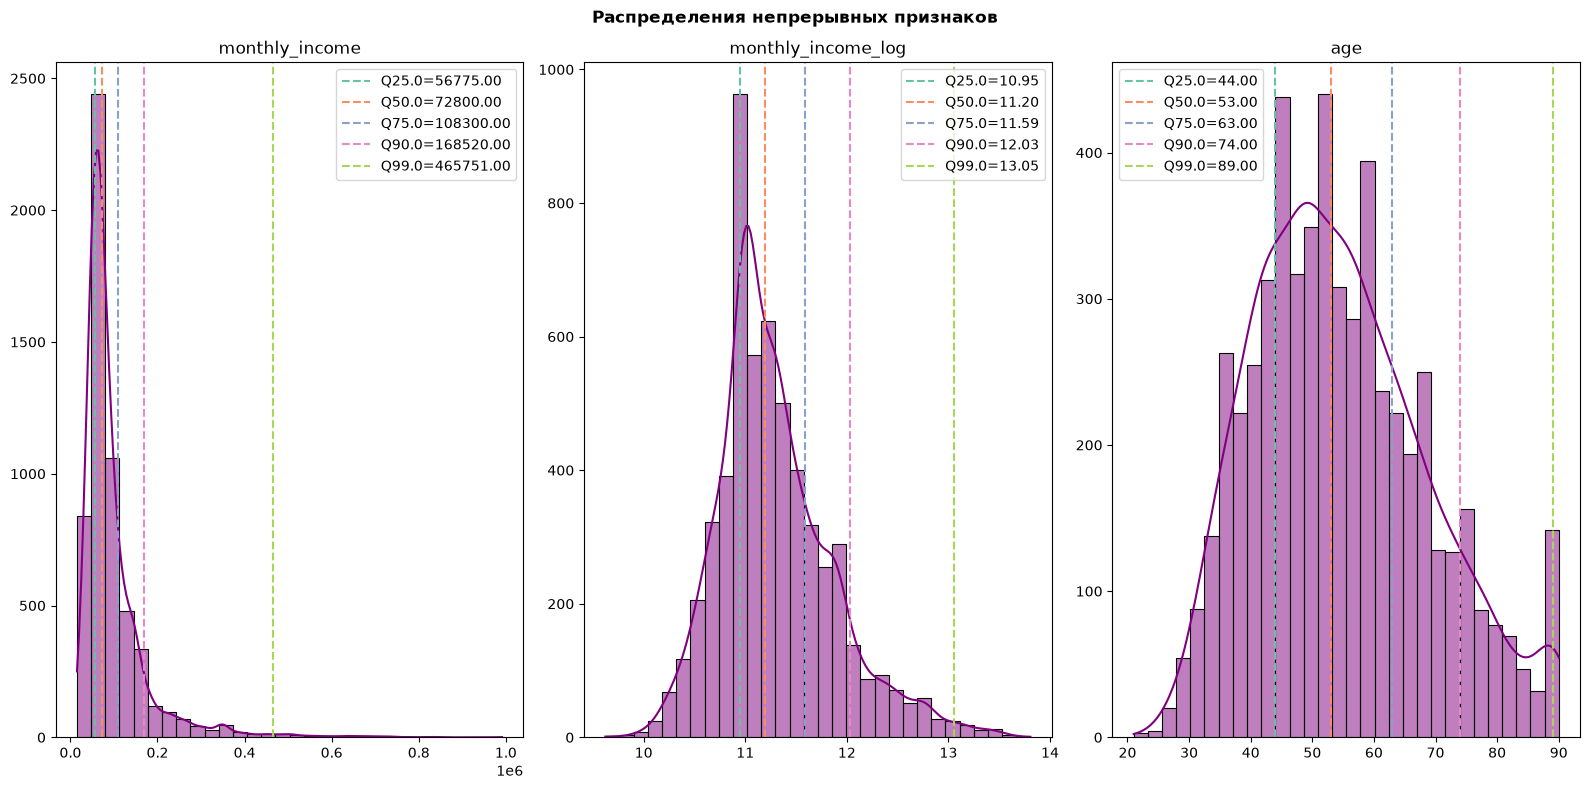

In [266]:
NUMERIC_COLS_CLIENTS = ["monthly_income", "monthly_income_log", "age"]
fig, axes = plt.subplots(1, 3, figsize=(16, 8))
for ax, col in zip(axes.ravel(), NUMERIC_COLS_CLIENTS):
    quantiles = clients_final[col].quantile([0.25, 0.5, 0.75, 0.9, 0.99])
    palette = sns.color_palette('Set2', n_colors=len(quantiles))
    sns.histplot(
        clients_final[col], bins=30, kde=True, 
        ax=ax, color="purple"
    )
    for (q, value), color in zip(quantiles.items(), palette):
        ax.axvline(
            value, 
            linestyle="--",
            label = f"Q{q*100}={value:.2f}",
            color=color
        )
    ax.set_title(f"{col}")
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.legend()
fig.suptitle("Распределения непрерывных признаков", fontweight="bold")

plt.tight_layout()
plt.show()

1) Сильная правая асимметрия у `monthly_income`, как и уточнялось ранее
2) 

**Transactions**

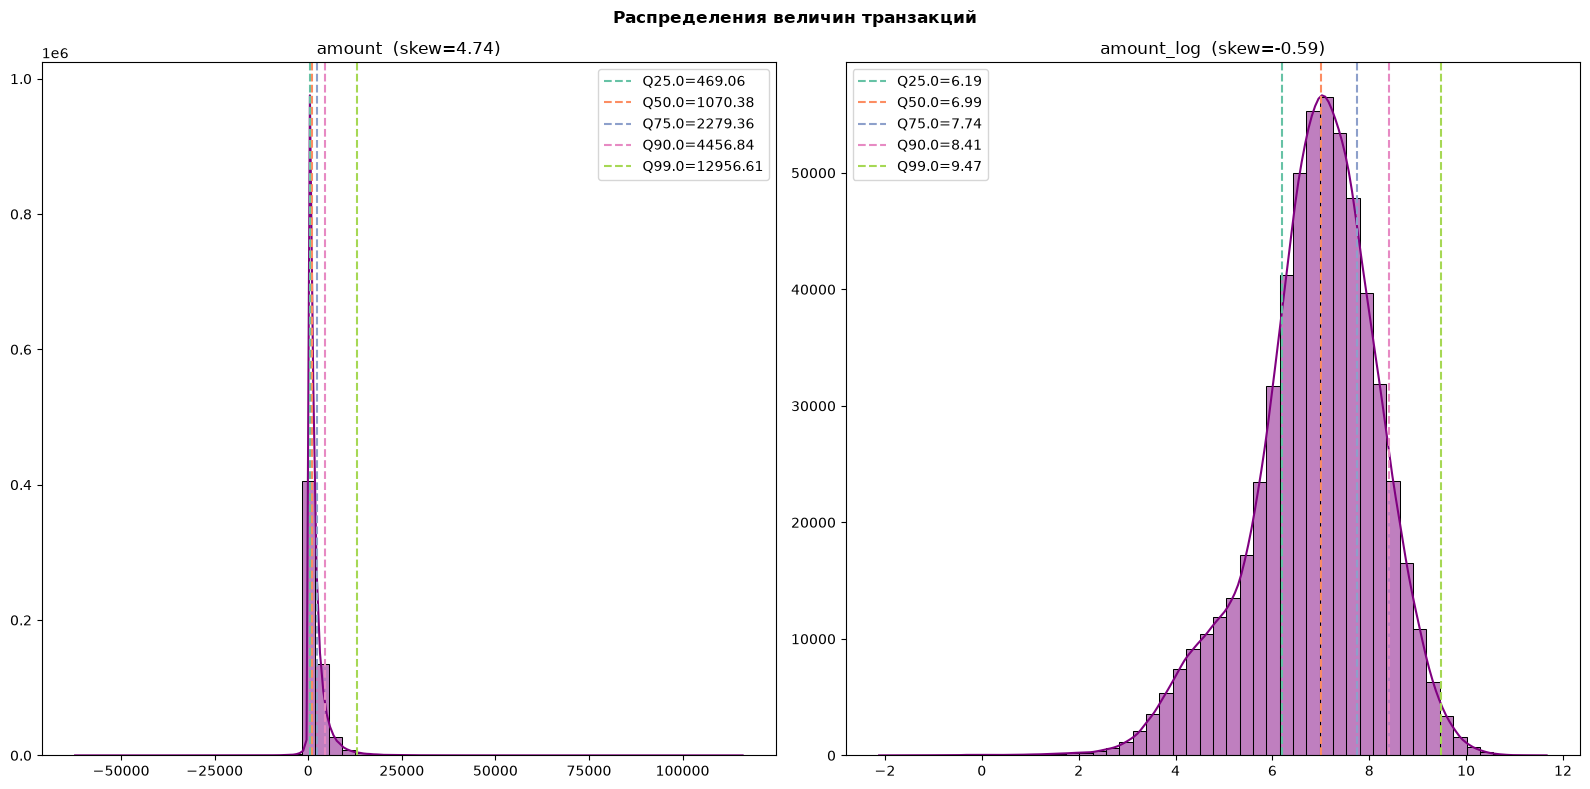

In [308]:
NUMERIC_COLS_TXN = ["amount", "amount_log"]
fig, axes = plt.subplots(1, 2, figsize=(16, 8))
for ax, col in zip(axes.ravel(), NUMERIC_COLS_TXN):
    quantiles = transactions_final[col].quantile([0.25, 0.5, 0.75, 0.9, 0.99])
    palette = sns.color_palette('Set2', n_colors=len(quantiles))
    sns.histplot(
        transactions_final[col], bins=50, kde=True, 
        ax=ax, color="purple"
    )
    for (q, value), color in zip(quantiles.items(), palette):
        ax.axvline(
            value, 
            linestyle="--",
            label = f"Q{q*100}={value:.2f}",
            color=color
        )
    ax.set_title(f"{col}  (skew={transactions_final[col].skew():.2f})")
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.legend()
fig.suptitle("Распределения величин транзакций", fontweight="bold")
plt.tight_layout()
plt.show()

### 5.2. Частотные характеристики категориальных признаков

**Clients**

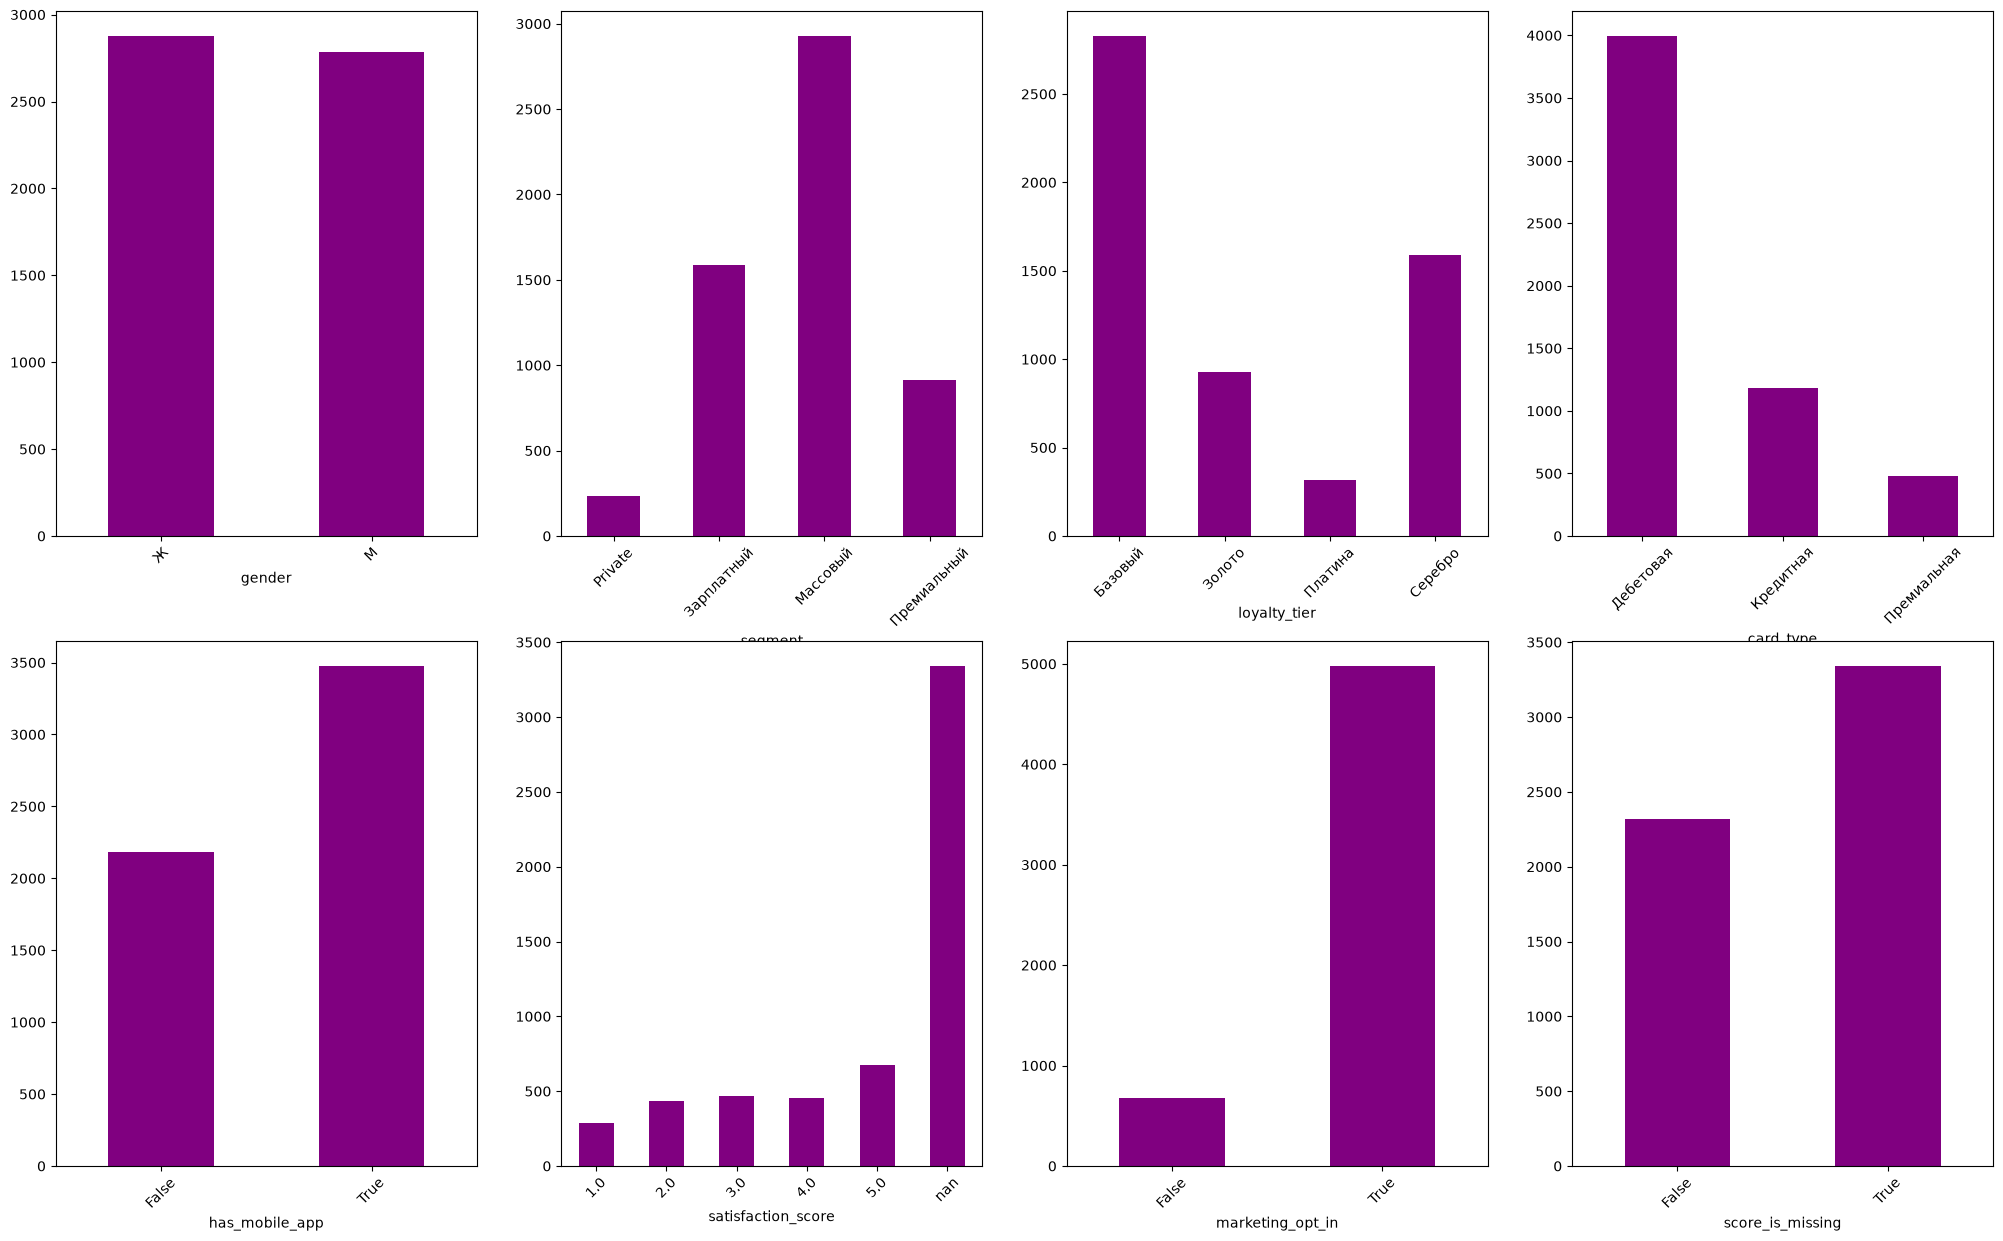

In [ ]:
# графики
CATEGORICAL_COLS_CLIENTS = clients_final.select_dtypes(include=["category", "bool", "boolean"]).columns.tolist()
fig, axes = plt.subplots(2, 4, figsize=(25, 15))
for ax, col in zip(axes.ravel(), CATEGORICAL_COLS_CLIENTS):
    # sns.barplot(clients_final[col].value_counts(dropna=False), 
    #             ax=ax,
    #             color="purple")
    clients_final[col].value_counts(dropna=False).sort_index().plot.bar(ax=ax, color='purple')
    ax.tick_params(axis='x', rotation=45)
plt.show()

In [241]:
# частотные характеристики
clients_final[CATEGORICAL_COLS_CLIENTS].describe().T

,count,unique,top,freq
gender,5660,2,Ж,2877
segment,5660,4,Массовый,2928
loyalty_tier,5660,4,Базовый,2828
card_type,5660,3,Дебетовая,3995
has_mobile_app,5660,2,True,3476
satisfaction_score,2319.0,5.0,5.0,673.0
marketing_opt_in,5660,2,True,4979
score_is_missing,5660,2,True,3341


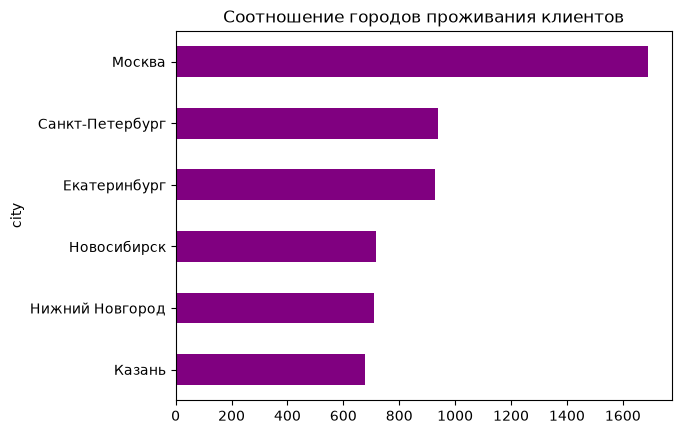

In [246]:
# отдельно посмотрим города
clients_final["city"].value_counts().plot.barh(title="Соотношение городов проживания клиентов",
                                               color="purple").invert_yaxis()
plt.show()

Выводы:


**Transactions**

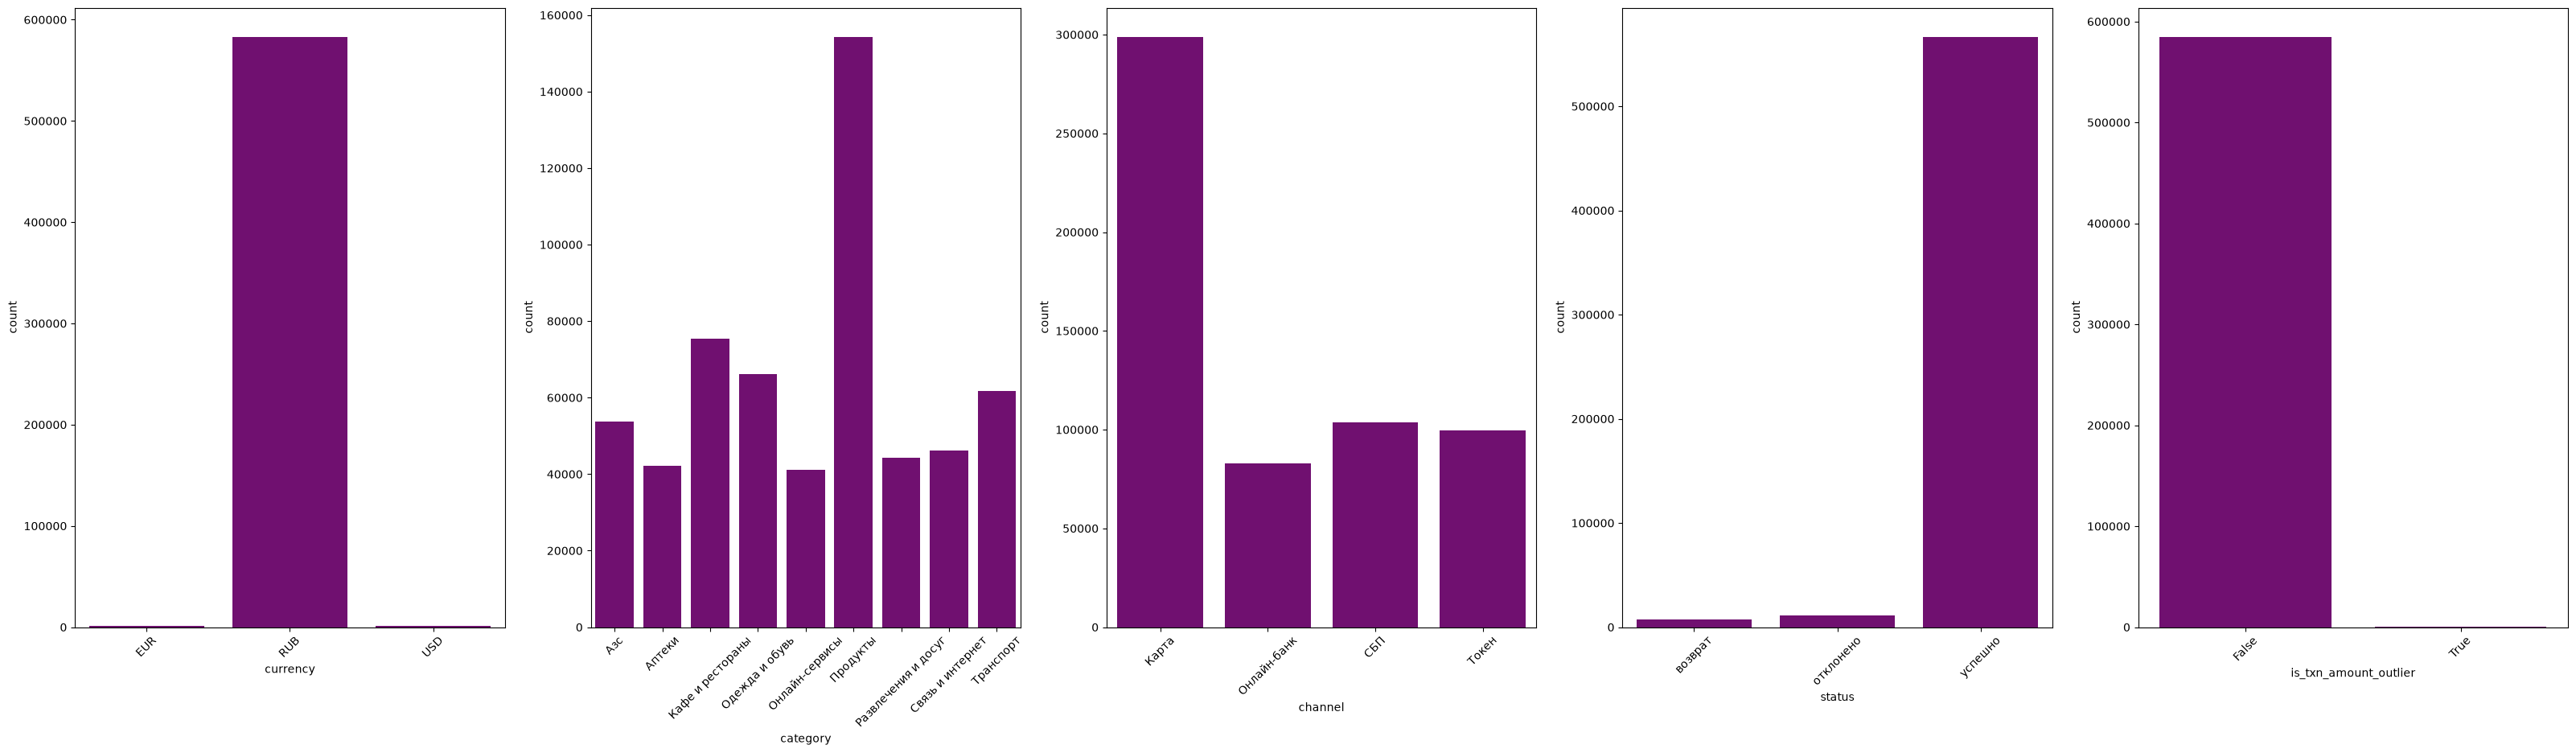

In [231]:
# графики
CATEGORICAL_COLS_TXN = transactions_final.select_dtypes(include=["category", "bool", "boolean"]).columns.tolist()
fig, axes = plt.subplots(1, 5, figsize=(40, 10))
for ax, col in zip(axes.ravel(), CATEGORICAL_COLS_TXN):
    sns.barplot(transactions_final[col].value_counts(dropna=False), 
                ax=ax,
                color="purple")
    ax.tick_params(axis='x', rotation=45)

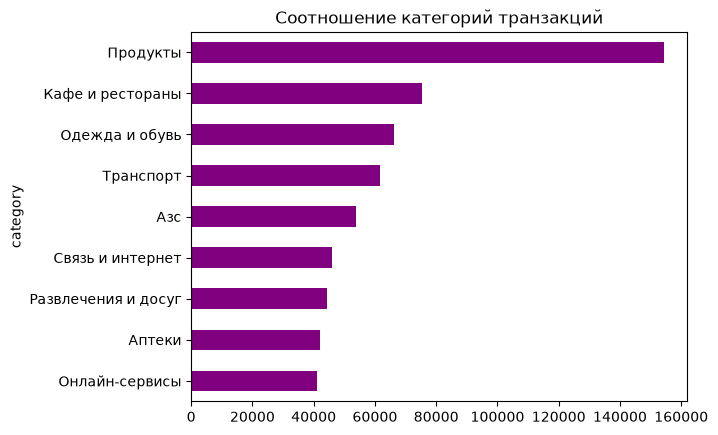

In [251]:
# отдельно посмотрим категории покупки
transactions_final["category"].value_counts().plot.barh(title="Соотношение категорий транзакций",
                                               color="purple").invert_yaxis()
plt.show()

In [253]:
transactions_final[CATEGORICAL_COLS_TXN].describe().T

,count,unique,top,freq
currency,585067,3,RUB,582711
category,585067,9,Продукты,154224
channel,585067,4,Карта,298693
status,585067,3,успешно,566354
is_txn_amount_outlier,585067,2,False,584480


Выводы:

### 5.3. Динамика по месяцам

Text(0.5, 1.0, 'Динамика кол-ва транзакций по месяцам')

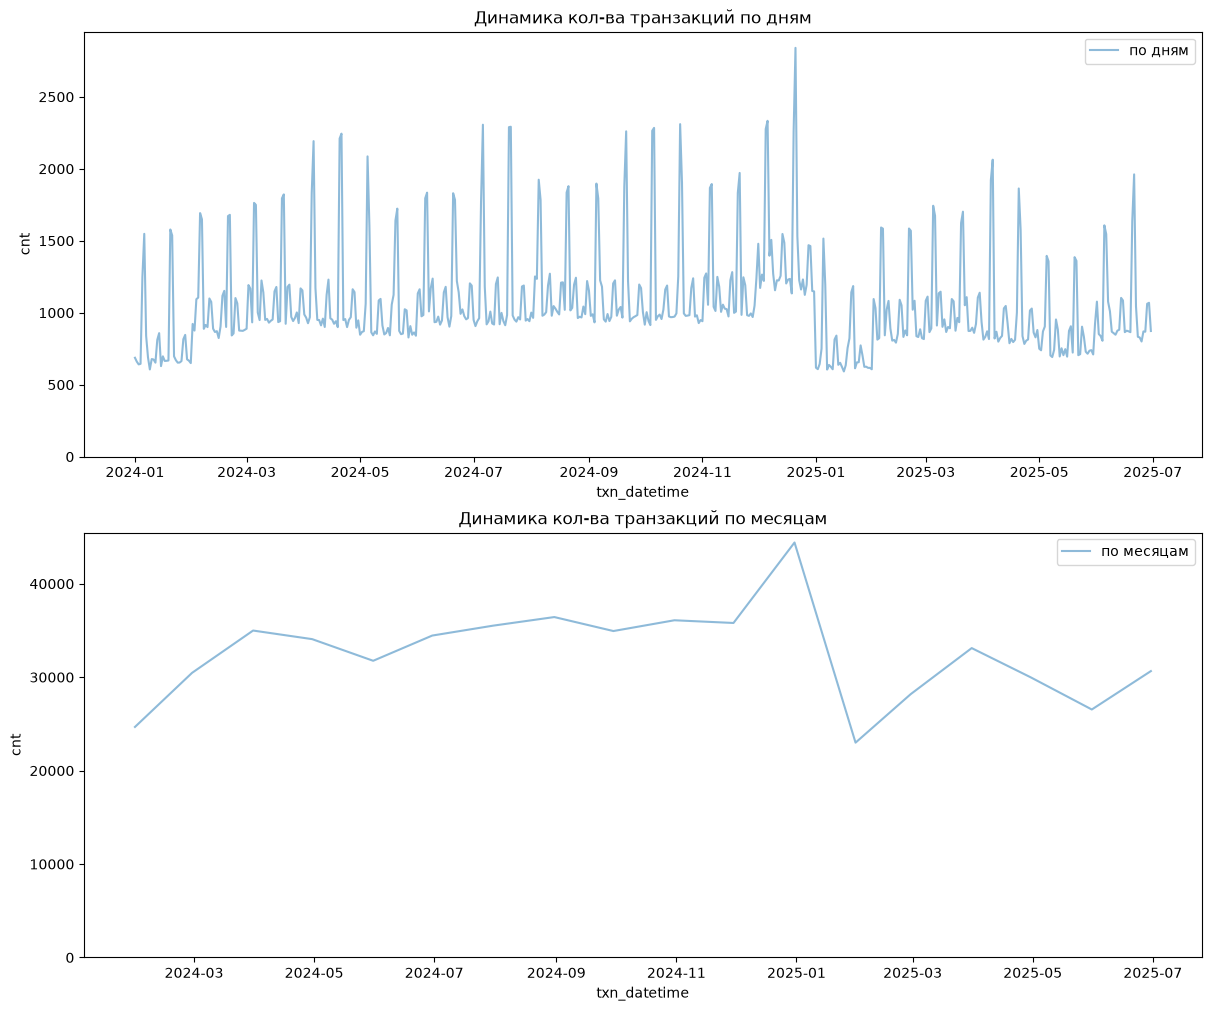

In [310]:
# 1. общая динамика по всему периоду
daily = (full_table.set_index("txn_datetime")["amount"]
        .resample("D").agg(["sum", "count"])
        .rename(columns={"sum": "total", "count": "cnt"})
        .reset_index())

monthly = (full_table.set_index("txn_datetime")["amount"]
          .resample("ME").agg(["sum", "count"])
          .rename(columns={"sum": "total", "count": "cnt"})
          .reset_index())

fig, axes = plt.subplots(2, 1, figsize=(12, 10), layout="constrained")
sns.lineplot(data=daily, x="txn_datetime", y="cnt", ax=axes[0], alpha=0.5, label="по дням")
sns.lineplot(data=monthly, x = "txn_datetime", y="cnt", ax=axes[1],  alpha=0.5, label="по месяцам")

axes[0].set_ylim(0, None)
axes[1].set_ylim(0, None)
axes[0].set_title("Динамика кол-ва транзакций по дням")
axes[1].set_title("Динамика кол-ва транзакций по месяцам")

Сравним одинаковые периоды месяцев (январь - июнь) для базового и оцениваемого периодов, чтобы понять сезонность

Text(0.5, 1.0, 'Сравнение кол-ва транзакций за 2024 и 2025 года')

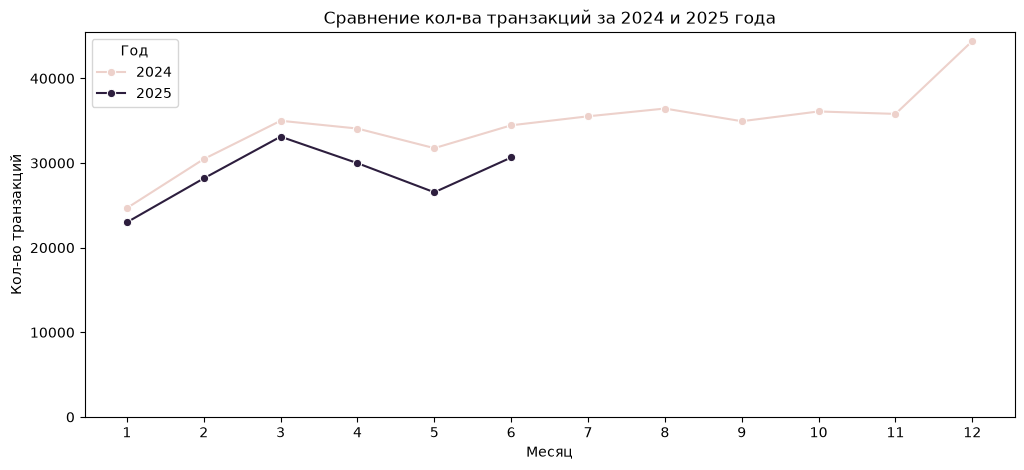

In [307]:
monthly["year"] = monthly.set_index("txn_datetime").index.year
monthly["month"] = monthly.set_index("txn_datetime").index.month

fig, ax = plt.subplots(figsize=(12, 5))
sns.lineplot(data=monthly, x="month", y="cnt", hue="year", marker="o", ax=ax)
ax.set_xticks(range(1, 13))
ax.set_xlabel("Месяц")
ax.set_ylabel("Кол-во транзакций")
ax.legend(title="Год")
ax.set_ylim(0, None)
ax.set_title("Сравнение кол-ва транзакций за 2024 и 2025 года")

Посмотрим только на транзакции, которые были оплачены картой

In [ ]:
transactions_cards = full_table.loc[full_table['channel'] == "Карта"]
monthly_сards = (transactions_cards.set_index("txn_datetime")["amount"]
          .resample("ME").agg(["sum", "count"])
          .rename(columns={"sum": "total", "count": "cnt"})
          .reset_index())

fig, ax = plt.subplots(figsize=(12, 10), layout="constrained")
sns.lineplot(data=monthly, x = "txn_datetime", y="cnt", ax=axes[1],  alpha=0.5, label="по месяцам")

axes[0].set_ylim(0, None)
axes[1].set_title("Динамика по месяцам ")

In [309]:
full_table

,txn_id,client_id,txn_datetime,amount,currency,category,mcc_code,channel,status,amount_log,is_txn_amount_outlier,birth_date,gender,city,segment,loyalty_tier,card_type,registration_date,card_open_date,income_source,monthly_income,has_mobile_app,app_last_login,satisfaction_score,branch_code,marketing_opt_in,score_is_missing,monthly_income_log
0,100001,C000952,2024-01-01 00:08:10,518.25,RUB,Кафе и рестораны,5812,Онлайн-банк,успешно,6.250458,False,1948-11-27,Ж,Москва,Зарплатный,Базовый,Дебетовая,2023-07-23,2023-10-20,Зарплата в нашем банке,46600.0,False,NaT,NaN,786,True,True,10.749356
1,100003,C005454,2024-01-01 02:43:12,1824.16,RUB,Связь и интернет,4814,Карта,успешно,7.508875,False,1963-03-08,М,Санкт-Петербург,Зарплатный,Серебро,Дебетовая,2019-07-10,2022-03-31,Зарплата в нашем банке,65200.0,True,2024-06-01,NaN,117,True,True,11.085215
2,100004,C002636,2024-01-01 03:12:15,1500.83,RUB,Продукты,5411,Токен,успешно,7.313774,False,2000-06-08,Ж,Москва,Премиальный,Платина,Дебетовая,2016-08-18,2018-07-10,Не указан,74800.0,True,2024-09-01,NaN,553,True,True,11.222573
3,100005,C005747,2024-01-01 03:22:11,2737.60,RUB,Продукты,5411,Карта,успешно,7.914837,False,1980-10-15,Ж,Москва,Массовый,Базовый,Дебетовая,2018-11-21,2020-05-15,Не указан,58800.0,True,2025-02-01,NaN,490,True,True,10.981897
4,100006,C003596,2024-01-01 04:14:19,254.25,RUB,Связь и интернет,4814,Карта,успешно,5.538318,False,1977-11-30,М,Новосибирск,Зарплатный,Базовый,Дебетовая,2019-03-28,2022-07-22,Зарплата в нашем банке,96500.0,True,2024-03-01,NaN,329,True,True,11.477298
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
585062,719183,C001077,2025-06-30 23:39:55,388.71,RUB,Связь и интернет,4814,Карта,успешно,5.962834,False,1980-03-23,М,Москва,Зарплатный,Базовый,Дебетовая,2014-12-06,2019-10-08,Зарплата в нашем банке,110000.0,False,NaT,NaN,453,True,True,11.608236
585063,719184,C005244,2025-06-30 23:40:20,5819.60,RUB,Азс,5541,Карта,успешно,8.668987,False,1991-12-23,М,Казань,Зарплатный,Серебро,Кредитная,2014-04-23,2016-05-11,Зарплата в нашем банке,67800.0,True,2024-01-01,NaN,370,False,True,11.124317
585064,719185,C001612,2025-06-30 23:44:46,689.21,RUB,Аптеки,5912,СБП,успешно,6.535546,False,1969-12-26,Ж,Екатеринбург,Массовый,Базовый,Дебетовая,2018-06-26,2020-10-05,Зарплата в другом банке,62800.0,True,2025-02-01,NaN,764,True,True,11.047710
585065,719186,C005212,2025-06-30 23:48:58,4969.25,RUB,Одежда и обувь,5651,Токен,успешно,8.511024,False,2000-10-23,Ж,Москва,Премиальный,Серебро,Кредитная,2012-07-02,2017-05-16,Зарплата в нашем банке,164200.0,True,2025-04-01,5.0,891,True,False,12.008840


### 5.4. Разрезы и связи между признаками

## 6. Метрика активности

Что именно вы считаете активностью, как она вычисляется, на каком
множестве клиентов, за какие окна. Отдельно: какое снижение эта метрика
**не увидит**.

In [ ]:
# может количество успешных(или всех) транзакций, осуществлённых картой

## 7. Поиск и описание групп

Правило отбора для каждой группы, её размер, причина падения.
Правило разрешения конфликтов, если клиент подходит под несколько групп.

### 7.1. Кого в кампанию не берём и почему

In [ ]:
# логично сразу не рассматривать тех, кто не согласен на коммуникацию, 
# т.к. на них не получится никак воздействовать для возвращения интереса


## 8. Что проверили и что не подтвердилось

Гипотезы, которые вы проверили и отвергли. По одной строке на гипотезу,
с числом.

## 9. Сохранение результатов

Три файла: очищенная таблица для второго ноутбука, журнал изменений,
итоговый список кампании.

In [ ]:
# clean.to_parquet("clean_data.parquet", index=False)
# cleaning_log.to_csv("cleaning_log.csv", index=False, encoding="utf-8")
# campaign[["client_id", "group"]].to_csv("campaign_list.csv", index=False, encoding="utf-8")